# <u>Entrega Final: Calidad del aire en la Ciudad de Buenos Aires </u>


**Dataset:** [Calidad de aire. Desde 2009 — Buenos Aires Data](https://data.buenosaires.gob.ar/dataset/calidad-aire/resource/juqdkmgo-291-resource) (espejo en [Kaggle](https://www.kaggle.com/datasets/marisasandroni/calidad-aire-caba)).

## Objetivo de este cuaderno

Esta es la entrega final del proyecto integrador. A lo largo del cuaderno se presenta el origen de los datos y el problema que se busca abordar, se analiza la estructura del dataset (filas, columnas, tipos de datos y valores faltantes), se identifican los problemas de calidad y se describen los procedimientos aplicados para resolverlos.

También se explica la construcción de la variable objetivo, la selección de las variables predictoras y los criterios utilizados para descartar aquellas que no se consideraron adecuadas. Posteriormente, se detalla la división de los datos en conjuntos de entrenamiento y prueba.

Finalmente, se entrenan y comparan distintos modelos de clasificación, se evalúan sus resultados mediante métricas de desempeño y se analizan sus principales limitaciones.



## 1. <u>Presentación del dataset</u>

### Origen

Los datos vienen del portal de datos abiertos del Gobierno de la Ciudad de Buenos Aires, ["Calidad de aire. Desde 2009"](https://www.google.com/url?q=https%3A%2F%2Fdata.buenosaires.gob.ar%2Fdataset%2Fcalidad-aire%2Fresource%2Fjuqdkmgo-291-resource). El cuaderno intenta descargarlos directamente desde ese portal oficial; si el sitio no está disponible, usa como respaldo la copia re-publicada en Kaggle como [Calidad Aire CABA](https://www.google.com/url?q=https%3A%2F%2Fwww.kaggle.com%2Fdatasets%2Fmarisasandroni%2Fcalidad-aire-caba), y como último recurso busca una copia guardada en Google Drive (`calidad-aire.csv`), que monta al principio del cuaderno.

### Descripción

El dataset contiene registros de mediciones de contaminantes atmosféricos de distintas estaciones de monitoreo de la Ciudad (Centenario, Córdoba, La Boca y Palermo), desde febrero de 2011. El período final depende de la versión de los datos utilizada. Por cada estación se reportan:

- `CO` — monóxido de carbono
- `NO2` — dióxido de nitrógeno
- `PM10` — material particulado (partículas en suspensión menores a 10 micrones)

Además de `FECHA` y `HORA`, cada columna de contaminante tiene el sufijo de la estación que la midió (por ejemplo, `PM10_PALERMO`).

### Problemática

La contaminación del aire es uno de los principales riesgos ambientales para la salud en zonas urbanas: la exposición al material particulado como el PM10 está asociada a efectos adversos sobre la salud respiratoria y cardiovascular, especialmente en poblaciones vulnerables. En una ciudad con tránsito vehicular tan denso como Buenos Aires, contar con información confiable sobre la calidad del aire puede servir tanto para estudiar el comportamiento de los contaminantes como para aportar información útil a la gestión pública y a la prevención de la exposición en momentos de mayor riesgo.

El problema concreto que abordo acá es si, a partir de las mediciones de contaminantes y las variables temporales disponibles, se puede clasificar un registro según presente un nivel de PM10 considerado elevado. Esto se plantea como un problema de clasificación binaria, que se desarrolla en las próximas secciones. La capacidad de anticipar episodios futuros dependerá de que las variables utilizadas estén disponibles antes del momento que se quiere predecir.

### Pregunta de investigación

¿Se puede clasificar la calidad del aire en la Ciudad de Buenos Aires como "no elevado" o "elevado" (nivel de PM10) a partir de las mediciones de contaminantes y las variables temporales disponibles?

### Descripción de contaminantes

PM10 (material particulado de diámetro aerodinámico menor o igual a 10 μm) mide la concentración de partículas en suspensión en el aire —como polvo, hollín y partículas provenientes de emisiones—, expresada habitualmente en μg/m³. Por su relación con efectos adversos sobre la salud, es el indicador elegido como base de la variable objetivo.

### Variable objetivo (y)

Voy a construir la variable binaria `calidad_aire`, con los valores "no elevado" o "elevado", tomando como referencia el promedio de PM10 entre estaciones (`PM10_promedio`). El valor de 45 μg/m³ corresponde a la guía de calidad del aire de la Organización Mundial de la Salud (OMS) para la media de 24 horas de PM10. Si se aplica directamente a registros horarios o a promedios calculados por registro, debe interpretarse como un umbral operativo para este proyecto, no como una evaluación oficial de la concentración media diaria. Si el promedio supera ese umbral, la clasifico como "elevado"; si no, como "no elevado".

Referencia: [Guías mundiales de calidad del aire de la OMS (2021)](https://www.who.int/publications/i/item/9789240034228).

### Por qué este dataset

Elegí este dataset porque tiene el tamaño justo para trabajar bien la limpieza sin que se extienda demasiado, y porque tiene problemas reales de calidad de datos —series temporales con faltantes, valores censurados y errores de formato—, así que sirve para practicar limpieza genuina y no un ejercicio artificial. Además, plantea un problema concreto de salud pública y un escenario de clasificación binaria que permitirá entrenar modelos y evaluar su capacidad para identificar registros con niveles elevados de PM10.

## 2. <u>Importar las bibliotecas necesarias</u>

Voy a utilizar las siguientes bibliotecas y módulos:

* **`os` y `time`**: para gestionar rutas de archivos y medir tiempos de ejecución durante el entrenamiento de los modelos.
* **`io` (`StringIO`) y `requests`**: para realizar solicitudes HTTP y leer contenido directamente desde el portal de datos.
* **`kagglehub`**: para descargar el dataset como alternativa de respaldo si no está disponible localmente o en la fuente oficial.
* **`numpy`**: para realizar operaciones numéricas vectorizadas.
* **`pandas`**: para la manipulación, limpieza y análisis exploratorio de estructuras de datos tabulares.
* **`matplotlib` y `seaborn`**: para generar visualizaciones y gráficos estadísticos.
* **`scikit-learn`**: para la división de conjuntos (train/test), el preprocesamiento de variables mediante *pipelines*, el entrenamiento de algoritmos de clasificación y la evaluación de su desempeño con métricas específicas.

Estas herramientas permiten realizar las distintas etapas del proyecto, desde la carga y exploración inicial de los datos hasta el entrenamiento y la evaluación comparativa de los modelos de clasificación.

In [ ]:
import os
from io import StringIO

import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    ConfusionMatrixDisplay
)



pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

## 3. <u>Cargar el dataset</u>

El cuaderno intenta descargar el dataset directamente desde el portal oficial de datos de la Ciudad de Buenos Aires. Si el sitio no está disponible o la descarga falla, utiliza como respaldo la copia republicada en Kaggle como [Calidad Aire CABA](https://www.kaggle.com/datasets/marisasandroni/calidad-aire-caba). Como último recurso, intenta cargar una copia guardada en Google Drive, que se monta únicamente si fallan las dos fuentes anteriores.

In [ ]:

URL_DATOS_ABIERTOS = "https://data.buenosaires.gob.ar/dataset/calidad-aire/resource/juqdkmgo-291-resource/download"

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/124.0.0.0 Safari/537.36"
    )
}

calidad_aire = None

# 1) Intento descargar directamente desde Buenos Aires Data
try:
    print("Intentando descargar dataset desde Buenos Aires Data...")
    resp = requests.get(URL_DATOS_ABIERTOS, headers=HEADERS, timeout=30)
    resp.raise_for_status()

    # Verifico que el servidor no haya devuelto una página HTML
    if (
        "Request Rejected" in resp.text[:200]
        or "text/html" in resp.headers.get("Content-Type", "").lower()
    ):
        raise ValueError(
            "El servidor devolvió HTML en lugar del CSV"
        )

    if not resp.content.strip():
        raise ValueError("La respuesta del servidor está vacía")

    calidad_aire = pd.read_csv(
        StringIO(resp.content.decode("utf-8-sig"))
    )
    print("Dataset descargado y cargado correctamente desde Buenos Aires Data")

except Exception as e:
    print("No se pudo descargar desde Buenos Aires Data:", e)

    # 2) Si falla, intento con Kaggle
    try:
        print("\nDescargando dataset desde Kaggle...")
        ruta_dataset = kagglehub.dataset_download(
            "marisasandroni/calidad-aire-caba"
        )

        archivos_csv = [
            f for f in os.listdir(ruta_dataset)
            if f.lower().endswith(".csv")
        ]
        print("Archivos encontrados en el dataset:", archivos_csv)

        if not archivos_csv:
            raise FileNotFoundError(
                "No se encontraron archivos CSV en el dataset de Kaggle"
            )

        ruta_csv = os.path.join(ruta_dataset, archivos_csv[0])
        calidad_aire = pd.read_csv(ruta_csv)
        print("Dataset descargado y cargado correctamente desde Kaggle")

    except Exception as e2:
        print("No se pudo descargar desde Kaggle:", e2)

        # 3) Respaldo: copia guardada en Google Drive
        # Solo se monta si fallaron las dos fuentes anteriores
        try:
            from google.colab import drive

            drive.mount("/content/drive")

            ruta_drive = (
                "/content/drive/MyDrive/Talento Tech 2026/"
                "ML 2026/Colab Notebooks ML 2026 - 26141/"
                "Entregas/Sandroni Marisa - ML2026 - 26141 - Pre Entrega/"
                "calidad-aire.csv"
            )

            calidad_aire = pd.read_csv(ruta_drive)
            print("Dataset cargado desde Google Drive")

        except Exception as e3:
            print(
                "No fue posible cargar el dataset desde Google Drive:",
                e3
            )
            raise


Intentando descargar dataset desde Buenos Aires Data...
Dataset descargado y cargado correctamente desde Buenos Aires Data


In [ ]:
calidad_aire.head()

,FECHA,HORA,CO_CENTENARIO,NO2_CENTENARIO,PM10_CENTENARIO,CO_CORDOBA,NO2_CORDOBA,PM10_CORDOBA,CO_LA_BOCA,NO2_LA_BOCA,PM10_LA_BOCA,CO_PALERMO,NO2_PALERMO,PM10_PALERMO
0,12FEB2011:00:00:00,19,s/d,s/d,s/d,0.20,22,28,0.08,21,s/d,NaN,NaN,NaN
1,13FEB2011:00:00:00,4,s/d,s/d,s/d,0.19,19,30,0.11,21,s/d,NaN,NaN,NaN
2,13FEB2011:00:00:00,7,s/d,s/d,s/d,0.14,20,27,0.11,28,s/d,NaN,NaN,NaN
3,13FEB2011:00:00:00,8,s/d,s/d,s/d,0.11,19,27,0.10,26,s/d,NaN,NaN,NaN
4,13FEB2011:00:00:00,11,s/d,s/d,s/d,0.06,14,26,0.07,7,s/d,NaN,NaN,NaN


 ***Observación inicial del dataset***

La visualización de los primeros registros me permite identificar la estructura general del conjunto de datos: fecha, hora y mediciones de CO, NO2 y PM10 correspondientes a cuatro estaciones de monitoreo de la Ciudad de Buenos Aires.

También se observan diferentes representaciones de datos no disponibles o incompletos, como `s/d`, `NaN`, `Na` y valores censurados expresados mediante el símbolo `<`. Estas situaciones serán consideradas durante la etapa de limpieza y preparación de los datos.

In [ ]:

# Guardar una copia intacta antes de la limpieza
calidad_aire_original = calidad_aire.copy(deep=True)


***Resguardo de los datos originales***

Antes de iniciar el proceso de limpieza, generé una copia independiente del dataset original mediante `copy(deep=True)`. Esto permite conservar los datos sin modificaciones y disponer de una referencia para comparar los resultados antes y después de las transformaciones.

## 4. <u>Análisis exploratorio inicial (EDA)</u>

Antes de realizar cualquier transformación, analizo la estructura y la calidad inicial del dataset. Para ello, reviso:

- La cantidad de filas y columnas.
- Los tipos de datos de cada variable.
- La presencia y distribución de valores faltantes.
- La distribución general de las variables.

**Una consideración importante:** los valores de los contaminantes no siempre se encuentran expresados como números. El portal de origen utiliza `s/d` para indicar que no hay un dato disponible y expresiones como `<0.05` para representar mediciones inferiores al límite de detección del instrumento.

Estas representaciones pueden provocar que pandas interprete algunas columnas como texto (`object`) en lugar de valores numéricos. Tengo en cuenta esta característica para analizar y definir posteriormente el tratamiento adecuado de los datos.

In [ ]:
# Muestro las dimensiones del dataset
print("\nCantidad de filas y columnas:")
print(calidad_aire.shape)

# Muestro los nombres de las columnas
print("\nColumnas disponibles:")
print(calidad_aire.columns.tolist())

# Muestro los tipos de datos de cada columna
print("\nTipos de datos:")
print(calidad_aire.dtypes)

# Reviso la cantidad de valores faltantes por columna
print("\nValores faltantes por columna:")
print(calidad_aire.isnull().sum())


Cantidad de filas y columnas:
(147470, 14)

Columnas disponibles:
['FECHA', 'HORA', 'CO_CENTENARIO', 'NO2_CENTENARIO', 'PM10_CENTENARIO', 'CO_CORDOBA', 'NO2_CORDOBA', 'PM10_CORDOBA', 'CO_LA_BOCA', 'NO2_LA_BOCA', 'PM10_LA_BOCA', 'CO_PALERMO', 'NO2_PALERMO', 'PM10_PALERMO']

Tipos de datos:
FECHA               object
HORA                 int64
CO_CENTENARIO       object
NO2_CENTENARIO      object
PM10_CENTENARIO     object
CO_CORDOBA          object
NO2_CORDOBA         object
PM10_CORDOBA        object
CO_LA_BOCA          object
NO2_LA_BOCA         object
PM10_LA_BOCA        object
CO_PALERMO          object
NO2_PALERMO        float64
PM10_PALERMO       float64
dtype: object

Valores faltantes por columna:
FECHA                   0
HORA                    0
CO_CENTENARIO         295
NO2_CENTENARIO        294
PM10_CENTENARIO     10599
CO_CORDOBA            295
NO2_CORDOBA           295
PM10_CORDOBA        10599
CO_LA_BOCA            293
NO2_LA_BOCA           294
PM10_LA_BOCA        10596

***Observaciones***

Al revisar la estructura del dataset, identifico 147.470 registros y 14 columnas. La mayoría de las variables de medición están almacenadas como texto (`object`), por lo que más adelante necesito convertirlas a un formato numérico para poder analizarlas correctamente.

También identifico diferencias importantes en la disponibilidad de datos entre las estaciones. Palermo presenta la mayor cantidad de valores faltantes: `CO_PALERMO` tiene aproximadamente un 95,9 % de datos ausentes, mientras que `NO2_PALERMO` y `PM10_PALERMO` no contienen registros disponibles.

En las demás estaciones, los faltantes de PM10 representan aproximadamente un 7,2 % de los registros, mientras que los de CO y NO2 son considerablemente menores.

Tengo en cuenta que este recuento contempla únicamente los valores que pandas reconoce como nulos (`NaN`). Todavía debo revisar las representaciones de ausencia o medición limitada que aparecen como texto, como `s/d`, `Na` y `<0.05`, antes de determinar la cantidad real de datos no disponibles.

In [ ]:
calidad_aire.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147470 entries, 0 to 147469
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   FECHA            147470 non-null  object 
 1   HORA             147470 non-null  int64  
 2   CO_CENTENARIO    147175 non-null  object 
 3   NO2_CENTENARIO   147176 non-null  object 
 4   PM10_CENTENARIO  136871 non-null  object 
 5   CO_CORDOBA       147175 non-null  object 
 6   NO2_CORDOBA      147175 non-null  object 
 7   PM10_CORDOBA     136871 non-null  object 
 8   CO_LA_BOCA       147177 non-null  object 
 9   NO2_LA_BOCA      147176 non-null  object 
 10  PM10_LA_BOCA     136874 non-null  object 
 11  CO_PALERMO       6002 non-null    object 
 12  NO2_PALERMO      0 non-null       float64
 13  PM10_PALERMO     0 non-null       float64
dtypes: float64(2), int64(1), object(11)
memory usage: 15.8+ MB


***Revisión de la estructura y los tipos de datos***

Con `info()` confirmo que el dataset contiene 147.470 registros y 14 columnas. También verifico que 11 columnas tienen formato `object`, una es de tipo `int64` y dos son `float64`.

Esta revisión confirma que necesito normalizar y convertir las variables de medición antes de realizar los análisis estadísticos y entrenar los modelos.

Además, confirmo que `NO2_PALERMO` y `PM10_PALERMO` no contienen ningún dato disponible, mientras que `CO_PALERMO` conserva una cantidad muy reducida de registros. Por este motivo, evaluaré su exclusión durante el proceso de limpieza.

In [ ]:
columnas_contaminantes = [c for c in calidad_aire.columns if c not in ["FECHA", "HORA"]]

print("Columnas de contaminantes detectadas:")
print(columnas_contaminantes)

print("\nAlgunos valores únicos de ejemplo (primera columna de contaminante):")
print(calidad_aire[columnas_contaminantes[0]].unique()[:20])

Columnas de contaminantes detectadas:
['CO_CENTENARIO', 'NO2_CENTENARIO', 'PM10_CENTENARIO', 'CO_CORDOBA', 'NO2_CORDOBA', 'PM10_CORDOBA', 'CO_LA_BOCA', 'NO2_LA_BOCA', 'PM10_LA_BOCA', 'CO_PALERMO', 'NO2_PALERMO', 'PM10_PALERMO']

Algunos valores únicos de ejemplo (primera columna de contaminante):
['s/d' '0.90' '0.66' '0.57' '0.55' '0.85' '0.76' '0.68' '1.11' '0.74'
 '0.54' '0.44' '0.43' '0.35' '0.26' '0.53' '0.38' '0.40' '0.49' '0.25']


***Identificación de valores no numéricos***

Identifico automáticamente las 12 columnas correspondientes a las mediciones de contaminantes, excluyendo las variables de fecha y hora.

Al inspeccionar los valores únicos de `CO_CENTENARIO`, confirmo que algunas mediciones están almacenadas como texto, aunque representan números. También encuentro indicadores como `s/d` y valores nulos (`NaN`).

Esta revisión me permite reconocer que, antes de convertir las columnas a formato numérico, necesito identificar y tratar las distintas representaciones de datos faltantes y mediciones registradas como texto.

Como sospechaba, encuentro valores como `s/d` y `<0.05` mezclados con mediciones numéricas, además de valores nulos (`NaN`). Voy a cuantificar cuántas apariciones tiene cada una de estas representaciones por columna antes de definir el tratamiento adecuado para cada caso.

In [ ]:

faltantes_sd = calidad_aire[columnas_contaminantes].apply(
    lambda col: col.astype(str).str.strip().str.lower().eq("s/d").sum()
)

print("Valores 's/d' por columna:")
print(faltantes_sd)

nulos_reales = calidad_aire.isnull().sum()

print("\nValores nulos (NaN) explícitos por columna:")
print(nulos_reales[nulos_reales > 0])


Valores 's/d' por columna:
CO_CENTENARIO      29643
NO2_CENTENARIO     29437
PM10_CENTENARIO    17022
CO_CORDOBA         34128
NO2_CORDOBA        49283
PM10_CORDOBA       36510
CO_LA_BOCA         35082
NO2_LA_BOCA        26238
PM10_LA_BOCA       21056
CO_PALERMO            60
NO2_PALERMO            0
PM10_PALERMO           0
dtype: int64

Valores nulos (NaN) explícitos por columna:
CO_CENTENARIO         295
NO2_CENTENARIO        294
PM10_CENTENARIO     10599
CO_CORDOBA            295
NO2_CORDOBA           295
PM10_CORDOBA        10599
CO_LA_BOCA            293
NO2_LA_BOCA           294
PM10_LA_BOCA        10596
CO_PALERMO         141468
NO2_PALERMO        147470
PM10_PALERMO       147470
dtype: int64


***Cuantificación de valores faltantes***

Al contabilizar las apariciones de `s/d`, identifico una cantidad importante de registros sin medición disponible en las distintas estaciones. También confirmo la presencia de valores nulos explícitos (`NaN`), que no se contabilizan como `s/d`.

Esta revisión demuestra que el recuento inicial de valores faltantes era incompleto, ya que pandas no reconoce automáticamente el texto `s/d` como un valor nulo.

Voy a considerar ambas representaciones en el proceso de limpieza y continuaré identificando otros formatos especiales, como las mediciones inferiores al límite de detección (`<0.05`), antes de decidir cómo tratar cada columna.

Ahora analizo la distribución general de los contaminantes. Para generar las visualizaciones, necesito convertir las columnas de mediciones a valores numéricos, por lo que realizo una conversión **provisoria**, únicamente con fines exploratorios.

En esta etapa, los valores que no puedan convertirse directamente se interpretarán como faltantes para los gráficos. Más adelante realizaré la limpieza definitiva y definiré el tratamiento de expresiones como `<0.05`. Durante esta exploración, conservaré intacto el dataset original y trabajaré sobre una copia.

In [ ]:

def a_numero_exploratorio(valor):
    """Conversión provisoria para explorar las distribuciones."""
    return pd.to_numeric(valor, errors="coerce")

exploratorio = calidad_aire[columnas_contaminantes].map(
    a_numero_exploratorio
)

exploratorio.describe()


,CO_CENTENARIO,NO2_CENTENARIO,PM10_CENTENARIO,CO_CORDOBA,NO2_CORDOBA,PM10_CORDOBA,CO_LA_BOCA,NO2_LA_BOCA,PM10_LA_BOCA,CO_PALERMO,NO2_PALERMO,PM10_PALERMO
count,117463.000000,117715.000000,119825.000000,111225.000000,97868.000000,100337.000000,103383.000000,120903.000000,115794.000000,5942.000000,0.0,0.0
mean,0.539997,17.942412,25.336274,0.619798,23.559080,26.020850,0.401465,20.943674,27.793685,1.001755,NaN,NaN
std,0.836616,9.118757,13.982293,0.986862,14.238677,13.016323,1.125182,11.933364,15.392614,0.459807,NaN,NaN
min,0.000000,-2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,0.350000,11.000000,17.000000,0.360000,14.000000,19.000000,0.200000,12.000000,19.000000,0.680000,NaN,NaN
50%,0.460000,17.000000,22.000000,0.530000,21.000000,24.000000,0.310000,19.000000,25.000000,0.960000,NaN,NaN
75%,0.630000,23.000000,30.000000,0.760000,30.000000,31.000000,0.460000,28.000000,33.000000,1.257500,NaN,NaN
max,49.950000,155.000000,427.000000,47.290000,283.000000,253.000000,44.730000,129.000000,387.000000,3.700000,NaN,NaN


***Estadísticas descriptivas de los contaminantes***

A partir de la conversión provisoria, obtengo las principales estadísticas descriptivas de cada contaminante. Identifico diferencias en la cantidad de mediciones disponibles entre las estaciones y confirmo que las columnas `NO2_PALERMO` y `PM10_PALERMO` no contienen observaciones numéricas.

También encuentro algunos valores extremos, como un máximo de 427 en `PM10_CENTENARIO` y de 387 en `PM10_LA_BOCA`, además de un valor mínimo de -2 en `NO2_CENTENARIO`, que revisaré durante el control de calidad.

Tengo en cuenta que estas estadísticas son preliminares, ya que los valores que no pudieron convertirse directamente, incluidos los registros `<0.05`, quedaron temporalmente excluidos del cálculo. No considero estos resultados como estadísticas definitivas del dataset.

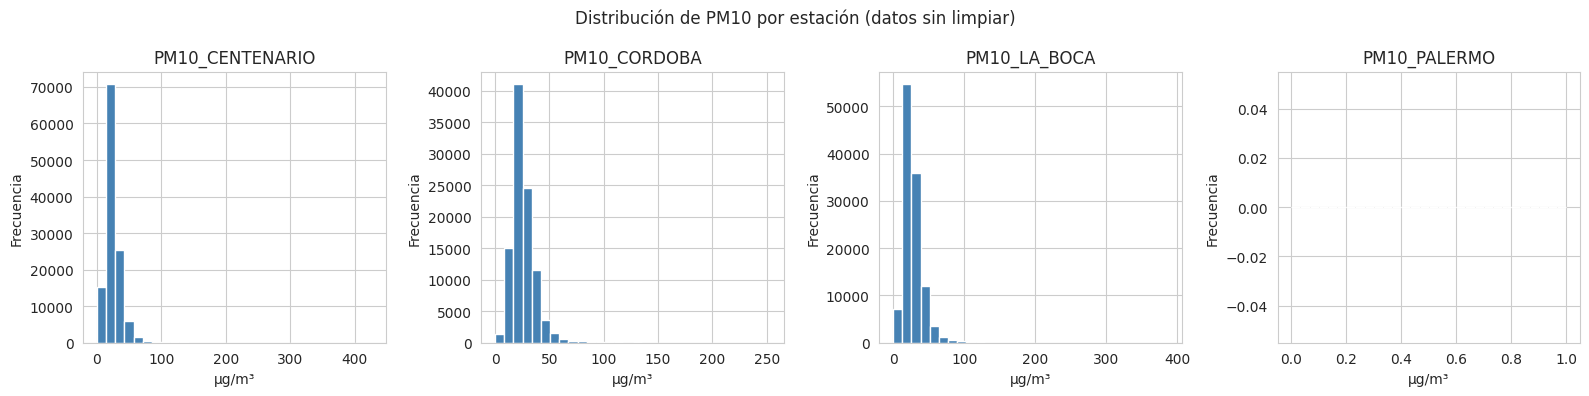

In [ ]:

columnas_pm10 = [
    c for c in columnas_contaminantes if "PM10" in c
]

if columnas_pm10:
    fig, axes = plt.subplots(
        1,
        len(columnas_pm10),
        figsize=(4 * len(columnas_pm10), 4),
        squeeze=False
    )

    for ax, col in zip(axes[0], columnas_pm10):
        ax.hist(
            exploratorio[col].dropna(),
            bins=30,
            color="steelblue"
        )
        ax.set_title(col)
        ax.set_xlabel("µg/m³")
        ax.set_ylabel("Frecuencia")

    plt.suptitle("Distribución de PM10 por estación (datos sin limpiar)")
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron columnas de PM10.")


***Distribución de PM10 por estación***

Represento mediante histogramas la distribución de las mediciones de PM10 en las estaciones Centenario, Córdoba, La Boca y Palermo.

Con esta visualización busco identificar la concentración de los valores, posibles asimetrías y observaciones extremas. Utilizo los datos de la conversión provisoria, por lo que los gráficos todavía no reflejan el tratamiento definitivo de los registros especiales y faltantes.

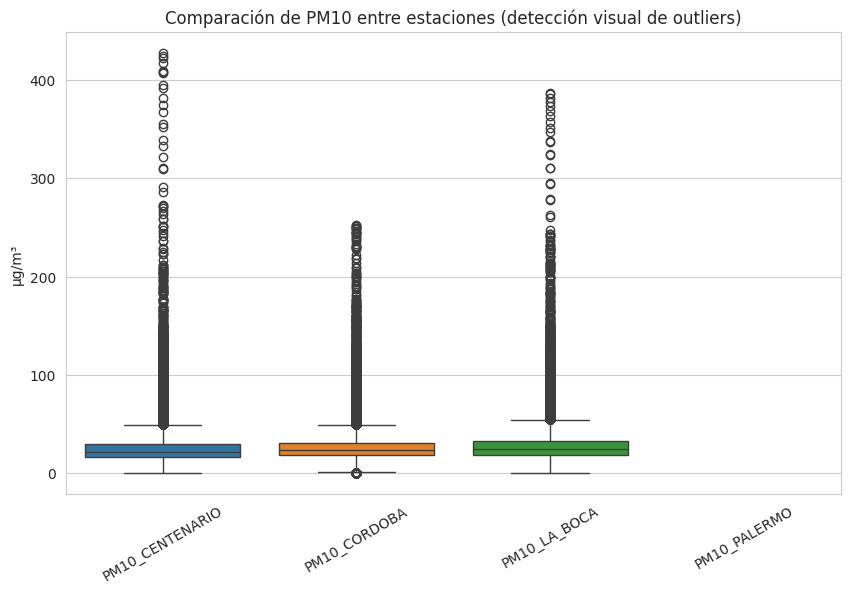

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=exploratorio[columnas_pm10])
plt.title("Comparación de PM10 entre estaciones (detección visual de outliers)")
plt.ylabel("µg/m³")
plt.xticks(rotation=30)
plt.show()

***Comparación de PM10 y detección visual de valores extremos***

Utilizo diagramas de cajas para comparar la distribución de las mediciones de PM10 entre las estaciones. A través de esta visualización puedo observar las medianas, la dispersión de los datos y los posibles valores extremos.

Esta comparación me permite identificar diferencias entre las estaciones y detectar registros que requieren una revisión más detallada antes de definir el tratamiento de los valores atípicos.

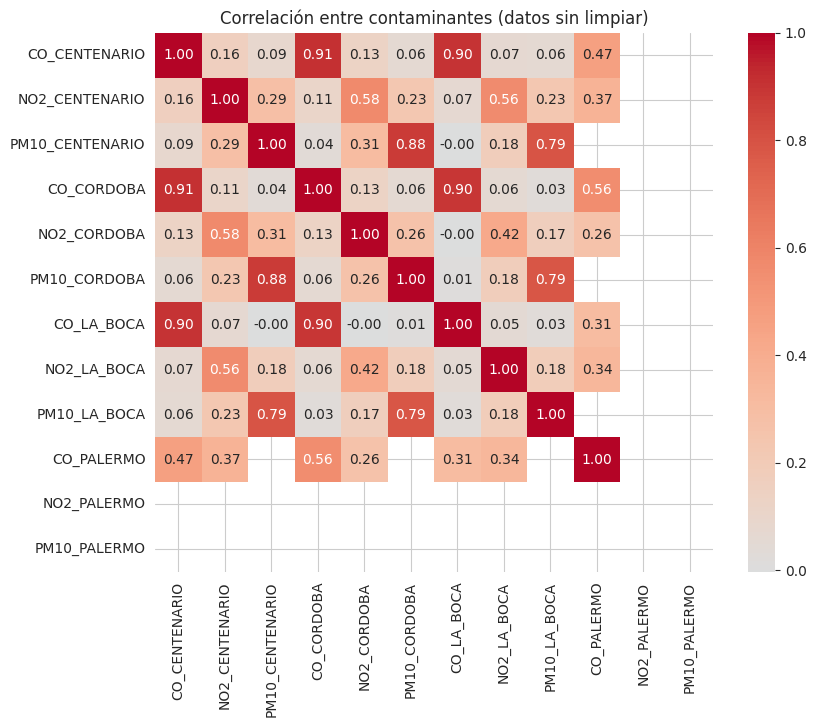

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(exploratorio.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre contaminantes (datos sin limpiar)")
plt.show()

***Correlación entre contaminantes***

Genero una matriz de correlación para explorar las relaciones lineales entre las mediciones de los distintos contaminantes y estaciones.

Utilizo el coeficiente de Pearson para identificar asociaciones positivas o negativas y conocer qué variables presentan comportamientos similares. Considero estos resultados como preliminares, ya que todavía no realicé la limpieza definitiva del dataset.

También tengo en cuenta que una correlación elevada indica asociación entre variables, pero no demuestra una relación de causa y efecto.

#### **Observaciones del EDA inicial**

A partir del análisis exploratorio, identifico una proporción elevada de valores `s/d` en varias columnas. Esto podría indicar que algunas estaciones comenzaron a registrar mediciones más tarde que otras o que tuvieron interrupciones en sus registros, aunque todavía necesito comprobarlo.

En los boxplots identifico posibles valores extremos en las mediciones de PM10. Considero que algunos podrían corresponder a picos reales de contaminación y otros a errores de registro. Por eso, durante la limpieza voy a revisar estos valores con cuidado, en lugar de eliminar automáticamente todas las observaciones que parezcan inusuales.

Por último, en la matriz de correlación observo que el CO presenta correlaciones muy altas entre estaciones (cercanas a 0,9), el NO2 correlaciones moderadas entre estaciones (0,4 a 0,6), y que CO y NO2 se relacionan débilmente entre sí. La correlación no demuestra causalidad. Las columnas de Palermo aparecen vacías en el heatmap porque no tienen datos.

Con estos resultados, cuento con una primera aproximación a la calidad y distribución de los datos, que me servirá como punto de partida para la etapa de limpieza y preparación.


## 5. <u>Limpieza de datos</u>

En esta etapa comienzo la limpieza y preparación del dataset. Primero reemplazo los indicadores `s/d` por valores nulos (`NaN`) y defino un criterio para tratar las mediciones censuradas, como `<0.05`. Si utilizo la mitad del umbral como aproximación, tengo presente que no representa una medición exacta.

Luego convierto `FECHA` a un formato `datetime`, verifico la existencia de registros duplicados y evalúo qué columnas o filas presentan una proporción excesiva de valores faltantes.

Por último, analizo los posibles valores extremos. Antes de decidir si corresponde modificarlos, considero su naturaleza y su posible relevancia para el problema que busco resolver. Evito aplicar transformaciones que puedan eliminar o distorsionar episodios de contaminación elevada que resulten importantes para la clasificación.


In [ ]:

def limpiar_valor(valor):
    if isinstance(valor, str):
        valor = valor.strip()

        if valor.lower() in ("s/d", ""):
            return np.nan

        if valor.startswith("<"):
            try:
                limite = float(valor[1:].strip())
                return limite / 2
            except ValueError:
                return np.nan

    try:
        return float(valor)
    except (TypeError, ValueError):
        return np.nan


# Conservo una copia de las columnas originales por seguridad
contaminantes_originales = calidad_aire[columnas_contaminantes].copy()

# Convierto los valores a numéricos
for col in columnas_contaminantes:
    calidad_aire[col] = calidad_aire[col].apply(limpiar_valor)

# Identifico y cuantifico los valores negativos antes de decidir su tratamiento
negativos = (calidad_aire[columnas_contaminantes] < 0).sum()

print("Valores negativos por columna:")
print(negativos[negativos > 0])

print("\nTipos de datos después de la conversión:")
print(calidad_aire[columnas_contaminantes].dtypes)

print("\nResumen estadístico:")
display(calidad_aire[columnas_contaminantes].describe())


Valores negativos por columna:
NO2_CENTENARIO    1
dtype: int64

Tipos de datos después de la conversión:
CO_CENTENARIO      float64
NO2_CENTENARIO     float64
PM10_CENTENARIO    float64
CO_CORDOBA         float64
NO2_CORDOBA        float64
PM10_CORDOBA       float64
CO_LA_BOCA         float64
NO2_LA_BOCA        float64
PM10_LA_BOCA       float64
CO_PALERMO         float64
NO2_PALERMO        float64
PM10_PALERMO       float64
dtype: object

Resumen estadístico:


,CO_CENTENARIO,NO2_CENTENARIO,PM10_CENTENARIO,CO_CORDOBA,NO2_CORDOBA,PM10_CORDOBA,CO_LA_BOCA,NO2_LA_BOCA,PM10_LA_BOCA,CO_PALERMO,NO2_PALERMO,PM10_PALERMO
count,117484.000000,117715.000000,119825.000000,112999.000000,97868.000000,100337.000000,112047.000000,120903.000000,115794.000000,5942.000000,0.0,0.0
mean,0.539904,17.942412,25.336274,0.610466,23.559080,26.020850,0.372355,20.943674,27.793685,1.001755,NaN,NaN
std,0.836570,9.118757,13.982293,0.981870,14.238677,13.016323,1.085472,11.933364,15.392614,0.459807,NaN,NaN
min,0.000000,-2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,0.350000,11.000000,17.000000,0.350000,14.000000,19.000000,0.160000,12.000000,19.000000,0.680000,NaN,NaN
50%,0.460000,17.000000,22.000000,0.530000,21.000000,24.000000,0.290000,19.000000,25.000000,0.960000,NaN,NaN
75%,0.630000,23.000000,30.000000,0.750000,30.000000,31.000000,0.450000,28.000000,33.000000,1.257500,NaN,NaN
max,49.950000,155.000000,427.000000,47.290000,283.000000,253.000000,44.730000,129.000000,387.000000,3.700000,NaN,NaN


In [ ]:
# Localizo los registros negativos de NO2_CENTENARIO
indices_negativos = calidad_aire.index[
    calidad_aire["NO2_CENTENARIO"] < 0
]

print("Índices de los registros negativos:")
print(indices_negativos.tolist())

# Comparo el valor original con el valor convertido
display(
    pd.DataFrame({
        "FECHA": calidad_aire.loc[indices_negativos, "FECHA"],
        "HORA": calidad_aire.loc[indices_negativos, "HORA"],
        "Valor original": contaminantes_originales.loc[
            indices_negativos, "NO2_CENTENARIO"
        ],
        "Valor convertido": calidad_aire.loc[
            indices_negativos, "NO2_CENTENARIO"
        ]
    })
)

Índices de los registros negativos:
[138202]


,FECHA,HORA,Valor original,Valor convertido
138202,13AUG2025:00:00:00,6,-2,-2.0


In [ ]:
# Trato el valor negativo de NO2_CENTENARIO como dato faltante
calidad_aire.loc[
    calidad_aire["NO2_CENTENARIO"] < 0,
    "NO2_CENTENARIO"
] = np.nan

print(
    "Valores negativos restantes:",
    (calidad_aire[columnas_contaminantes] < 0).sum().sum()
)

Valores negativos restantes: 0


***Tratamiento de valores negativos***

Al revisar los valores negativos, identifico un único registro en `NO2_CENTENARIO`, correspondiente al 13 de agosto de 2025 a las 06:00, con un valor de -2.

Considero que este valor no representa una concentración físicamente válida, por lo que lo reemplazo por `NaN`. No lo sustituyo por cero ni por una estimación, ya que no dispongo de información suficiente para determinar su valor real.

Ahora convierto la columna `FECHA` al tipo de dato `datetime`. Como el formato original contiene abreviaturas de meses en inglés, por ejemplo `08NOV2013:00:00:00`, preparo un diccionario para traducirlas al español antes de realizar la conversión. De esta manera, controlo la interpretación de las fechas y evito depender de la configuración regional del entorno.

Esta transformación me permitirá trabajar con las fechas de forma consistente y extraer variables temporales para el análisis posterior.

In [ ]:
meses = {
    "ENE": "01", "JAN": "01",
    "FEB": "02",
    "MAR": "03",
    "ABR": "04", "APR": "04",
    "MAY": "05",
    "JUN": "06",
    "JUL": "07",
    "AGO": "08", "AUG": "08",
    "SEP": "09",
    "OCT": "10",
    "NOV": "11",
    "DIC": "12", "DEC": "12",
}

def convertir_fecha(fecha_str):
    partes = str(fecha_str).split(":")[0]  # ej. "08NOV2013"
    dia = partes[:2]
    mes_abrev = partes[2:5].upper()
    anio = partes[5:9]
    mes = meses.get(mes_abrev, np.nan)
    if pd.isna(mes):
        return np.nan
    return f"{anio}-{mes}-{dia}"

calidad_aire["fecha"] = pd.to_datetime(
    calidad_aire["FECHA"].apply(convertir_fecha),
    errors="coerce"
)

print("Fechas que no se pudieron convertir:", calidad_aire["fecha"].isna().sum())
calidad_aire[["FECHA", "fecha", "HORA"]].head()

Fechas que no se pudieron convertir: 0


,FECHA,fecha,HORA
0,12FEB2011:00:00:00,2011-02-12,19
1,13FEB2011:00:00:00,2011-02-13,4
2,13FEB2011:00:00:00,2011-02-13,7
3,13FEB2011:00:00:00,2011-02-13,8
4,13FEB2011:00:00:00,2011-02-13,11


***Conversión de fechas***

Convierto correctamente los registros de la columna `FECHA` al formato `datetime`, utilizando un diccionario de meses para interpretar las abreviaturas en español e inglés.

La conversión se realizó sin errores: no encontré fechas que hayan quedado como valores nulos. Además, conservo la columna original y genero una nueva columna llamada `fecha`, que utilizaré para los análisis temporales posteriores.

In [ ]:
duplicados = calidad_aire.duplicated().sum()
print(f"Filas duplicadas encontradas: {duplicados}")

if duplicados > 0:
    calidad_aire = calidad_aire.drop_duplicates()
    print("Duplicados eliminados. Nueva forma del dataset:", calidad_aire.shape)

Filas duplicadas encontradas: 0


***Verificación de registros duplicados***

Reviso si existen filas duplicadas en el dataset, considerando el conjunto completo de columnas. El resultado indica que no encuentro registros repetidos, por lo que no necesito eliminar ninguna fila en esta etapa.

Conservo así los 147.470 registros originales.

In [ ]:
porcentaje_nulos = calidad_aire[columnas_contaminantes].isnull().mean().sort_values(ascending=False) * 100
print("Porcentaje de valores faltantes por columna:")
print(porcentaje_nulos.round(1))

Porcentaje de valores faltantes por columna:
PM10_PALERMO       100.0
NO2_PALERMO        100.0
CO_PALERMO          96.0
NO2_CORDOBA         33.6
PM10_CORDOBA        32.0
CO_LA_BOCA          24.0
CO_CORDOBA          23.4
PM10_LA_BOCA        21.5
CO_CENTENARIO       20.3
NO2_CENTENARIO      20.2
PM10_CENTENARIO     18.7
NO2_LA_BOCA         18.0
dtype: float64


***Análisis del porcentaje de valores faltantes***

Calculo el porcentaje de valores faltantes en cada columna de contaminantes para evaluar la disponibilidad de información por estación.

Identifico que `PM10_PALERMO` y `NO2_PALERMO` presentan un 100 % de valores faltantes, mientras que `CO_PALERMO` alcanza el 96 %. En las demás columnas, los porcentajes varían entre el 18 % y el 33,6 %.

Estos resultados confirman que las mediciones de Palermo tienen una disponibilidad muy limitada. Voy a utilizar esta información para fundamentar la selección de columnas durante la limpieza, teniendo en cuenta también la relevancia de cada contaminante para el objetivo del proyecto.

***Criterio de limpieza de valores faltantes***

Cuando una columna presenta un porcentaje muy elevado de valores faltantes, evalúo excluirla como variable predictora, ya que imputar la mayoría de sus registros podría reducir la confiabilidad de la información.

Para las columnas que conservo, utilizo la mediana como criterio de imputación, porque es una medida menos sensible a los valores extremos que la media.

Para evitar la fuga de información (*data leakage*), ajusto la imputación únicamente con los datos de entrenamiento y luego aplico esa misma transformación a los datos de prueba.

Defino el umbral mediante la variable `UMBRAL_FALTANTES`, en lugar de decidir manualmente qué columnas eliminar. De esta manera, mantengo un criterio explícito, reproducible y fácil de ajustar.

In [ ]:

UMBRAL_FALTANTES = 60  # porcentaje

columnas_descartadas = porcentaje_nulos[
    porcentaje_nulos > UMBRAL_FALTANTES
].index.tolist()

columnas_utiles = [
    c for c in columnas_contaminantes
    if c not in columnas_descartadas
]

print("Columnas descartadas por exceso de faltantes:")
print(columnas_descartadas)

print("\nColumnas de contaminantes que seguimos usando:")
print(columnas_utiles)

print(
    "\nValores nulos en las columnas útiles antes de la imputación:",
    calidad_aire[columnas_utiles].isnull().sum().sum()
)


Columnas descartadas por exceso de faltantes:
['PM10_PALERMO', 'NO2_PALERMO', 'CO_PALERMO']

Columnas de contaminantes que seguimos usando:
['CO_CENTENARIO', 'NO2_CENTENARIO', 'PM10_CENTENARIO', 'CO_CORDOBA', 'NO2_CORDOBA', 'PM10_CORDOBA', 'CO_LA_BOCA', 'NO2_LA_BOCA', 'PM10_LA_BOCA']

Valores nulos en las columnas útiles antes de la imputación: 312259


***Selección de columnas según el porcentaje de faltantes***

Establezco un umbral del 60 % para identificar las columnas con una proporción excesiva de valores faltantes. Al aplicar este criterio, descarto `PM10_PALERMO`, `NO2_PALERMO` y `CO_PALERMO`, ya que las tres superan el porcentaje definido.

Conservo nueve columnas correspondientes a las estaciones Centenario, Córdoba y La Boca. En estas variables todavía identifico 312.259 valores nulos que deberé tratar durante la preparación de los datos para el modelado.

De esta manera, reduzco la cantidad de variables con información insuficiente sin descartar las mediciones disponibles en las demás estaciones.

Para tratar los valores extremos, evito eliminar filas, ya que podría perder registros que contienen información útil sobre otros contaminantes. Analizo los valores extremos y su posible impacto, teniendo en cuenta que no todos representan errores: algunos pueden corresponder a episodios reales de contaminación elevada.

Por este motivo, decido conservar las mediciones originales y evitar el recorte automático entre los percentiles 1 y 99, especialmente en PM10, que utilizaré para construir la variable objetivo del modelo.

Si más adelante considero necesario acotar alguna variable predictora, justificaré el criterio y calcularé los límites únicamente con los datos de entrenamiento, para evitar la fuga de información (*data leakage*).

In [ ]:
# Analizo los valores extremos sin modificar las mediciones originales
calidad_aire[columnas_utiles].describe()

,CO_CENTENARIO,NO2_CENTENARIO,PM10_CENTENARIO,CO_CORDOBA,NO2_CORDOBA,PM10_CORDOBA,CO_LA_BOCA,NO2_LA_BOCA,PM10_LA_BOCA
count,117484.000000,117714.000000,119825.000000,112999.000000,97868.000000,100337.000000,112047.000000,120903.000000,115794.000000
mean,0.539904,17.942581,25.336274,0.610466,23.559080,26.020850,0.372355,20.943674,27.793685
std,0.836570,9.118610,13.982293,0.981870,14.238677,13.016323,1.085472,11.933364,15.392614
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.350000,11.000000,17.000000,0.350000,14.000000,19.000000,0.160000,12.000000,19.000000
50%,0.460000,17.000000,22.000000,0.530000,21.000000,24.000000,0.290000,19.000000,25.000000
75%,0.630000,23.000000,30.000000,0.750000,30.000000,31.000000,0.450000,28.000000,33.000000
max,49.950000,155.000000,427.000000,47.290000,283.000000,253.000000,44.730000,129.000000,387.000000


***Observaciones sobre los valores extremos***

Al revisar las estadísticas descriptivas, identifico diferencias importantes entre los valores centrales y los máximos de algunos contaminantes. En particular, encuentro máximos de PM10 de 427 μg/m³ en Centenario, 253 μg/m³ en Córdoba y 387 μg/m³ en La Boca.

Estos valores representan observaciones extremas que requieren atención, pero no puedo considerarlos errores únicamente por su magnitud. Algunos podrían corresponder a episodios reales de contaminación elevada.

Por este motivo, decido conservar las mediciones originales y evitar el recorte automático de valores extremos, especialmente en PM10, ya que utilizaré este contaminante para construir la variable objetivo del modelo.

## 6. <u>Transformaciones básicas</u>

### 6.1 <u>Creación de variables</u>

A partir de las columnas `fecha` y `HORA`, construyo nuevas variables temporales que podrían ayudar a identificar patrones en las mediciones de contaminantes. Para ello, extraigo el **mes**, identifico si cada registro corresponde a un **fin de semana** y clasifico la fecha según la **estación del año**.

También calculo, para cada contaminante, un **promedio entre las estaciones de monitoreo** (`CO_promedio`, `NO2_promedio` y `PM10_promedio`). De esta manera, resumo las mediciones disponibles en una variable por contaminante, en lugar de trabajar únicamente con las mediciones individuales de cada estación.

Tengo en cuenta que estos promedios pueden ocultar diferencias geográficas y que la cantidad de mediciones disponibles puede variar entre estaciones. Por eso, considero los valores faltantes al realizar los cálculos y verifico que el promedio represente adecuadamente la información disponible.

In [ ]:

calidad_aire["mes"] = calidad_aire["fecha"].dt.month
calidad_aire["dia_semana"] = calidad_aire["fecha"].dt.dayofweek  # 0 = lunes
calidad_aire["es_fin_de_semana"] = calidad_aire["dia_semana"].isin([5, 6]).astype(int)

def mes_a_estacion(mes):
    if mes in [12, 1, 2]:
        return "verano"
    elif mes in [3, 4, 5]:
        return "otonio"
    elif mes in [6, 7, 8]:
        return "invierno"
    else:
        return "primavera"

calidad_aire["estacion_anio"] = calidad_aire["mes"].apply(mes_a_estacion)

for contaminante in ["CO", "NO2"]:
    columnas_del_contaminante = [
        c for c in columnas_utiles if c.startswith(contaminante)
    ]
    if columnas_del_contaminante:
        calidad_aire[f"{contaminante}_promedio"] = (
            calidad_aire[columnas_del_contaminante].mean(axis=1)
        )

calidad_aire[
    ["fecha", "mes", "dia_semana", "es_fin_de_semana",
     "estacion_anio", "CO_promedio", "NO2_promedio"]
].head()


,fecha,mes,dia_semana,es_fin_de_semana,estacion_anio,CO_promedio,NO2_promedio
0,2011-02-12,2,5,1,verano,0.140,21.5
1,2011-02-13,2,6,1,verano,0.150,20.0
2,2011-02-13,2,6,1,verano,0.125,24.0
3,2011-02-13,2,6,1,verano,0.105,22.5
4,2011-02-13,2,6,1,verano,0.065,10.5


***Creación de variables temporales y promedios***

Creo las variables temporales `mes`, `dia_semana`, `es_fin_de_semana` y `estacion_anio` a partir de la fecha de cada registro.

También calculo los promedios de CO y NO2 entre las estaciones disponibles. Para estos cálculos, pandas ignora automáticamente los valores nulos y utiliza las mediciones existentes en cada fila.

Tengo en cuenta que la cantidad de estaciones disponibles puede variar entre registros, por lo que estos promedios no siempre representan la misma cantidad de mediciones.

### 6.2 <u>Variable objetivo (`y`)</u>

A partir de `PM10_promedio`, construyo una variable objetivo categórica que identifica los registros con concentraciones de PM10 elevadas.

Tomo como referencia el valor guía de la OMS de 45 µg/m³ para un promedio de 24 horas. Como mi dataset contiene registros horarios, utilizo este valor como **umbral operativo del proyecto**, y no como una evaluación directa del cumplimiento de la recomendación diaria.

De esta manera, clasifico los registros en dos categorías: **PM10 no elevado** y **PM10 elevado**, según si el promedio se encuentra por debajo o supera el umbral establecido.



In [ ]:

# Construyo el objetivo a partir de mediciones originales de PM10,
# antes de imputar faltantes o acotar valores extremos.

UMBRAL_PM10 = 45  # µg/m³; umbral operativo del proyecto

# Identificar las columnas originales de PM10
pm10_cols_originales = [
    c for c in calidad_aire_original.columns
    if c.startswith("PM10_")
]

# Convertir a números; los valores no numéricos quedan como NaN.
# No se imputan ni se acotan las mediciones para construir el objetivo.
pm10_original = calidad_aire_original[pm10_cols_originales].apply(
    pd.to_numeric, errors="coerce"
)

# Promedio de las mediciones originales disponibles por registro.
# Si todas faltan, el promedio queda como NaN.
pm10_promedio_original = pm10_original.mean(axis=1)

# Asignar el promedio original al dataset de trabajo
calidad_aire["PM10_promedio"] = pm10_promedio_original

# Crear el objetivo solo para los registros con PM10 válido
calidad_aire["calidad_aire"] = pd.Series(
    index=calidad_aire.index, dtype="object"
)

validos = calidad_aire["PM10_promedio"].notna()

calidad_aire.loc[validos, "calidad_aire"] = np.where(
    calidad_aire.loc[validos, "PM10_promedio"] <= UMBRAL_PM10,
    "no elevado",
    "elevado"
)

print("Registros con PM10 válido:", int(validos.sum()))
print("Registros sin PM10 válido:", int((~validos).sum()))
print("\nDistribución del objetivo:")
print(calidad_aire["calidad_aire"].value_counts(dropna=False))
print("\nProporciones:")
print(
    calidad_aire["calidad_aire"]
    .value_counts(normalize=True)
    .round(3)
)


Registros con PM10 válido: 135480
Registros sin PM10 válido: 11990

Distribución del objetivo:
calidad_aire
no elevado    127318
NaN            11990
elevado         8162
Name: count, dtype: int64

Proporciones:
calidad_aire
no elevado    0.94
elevado       0.06
Name: proportion, dtype: float64


***Distribución de la variable objetivo***

Construyo la variable objetivo utilizando las mediciones originales de PM10, sin imputar los valores faltantes ni modificar los valores extremos.

Obtengo 135.480 registros con mediciones válidas y 11.990 registros sin información suficiente para asignar una categoría. Entre los registros clasificados, identifico 127.318 casos con PM10 no elevado (94 %) y 8.162 casos con PM10 elevado (6 %).

Esta distribución muestra un desequilibrio entre las categorías, aspecto que tendré en cuenta al evaluar el rendimiento de los modelos de clasificación.

In [ ]:

# Comprobación de integridad de la variable objetivo

# Recalcular el promedio desde las mediciones originales
promedio_verificacion = pm10_original.mean(axis=1)

# Verificar que el promedio usado coincida con el original
coinciden = np.isclose(
    calidad_aire["PM10_promedio"],
    promedio_verificacion,
    equal_nan=True
).all()

# Verificar que no haya etiquetas en registros sin PM10 válido
sin_pm10_con_etiqueta = (
    calidad_aire["PM10_promedio"].isna()
    & calidad_aire["calidad_aire"].notna()
).sum()

# Verificar que todos los registros etiquetados tengan PM10 válido
etiquetados_sin_pm10 = (
    calidad_aire["calidad_aire"].notna()
    & calidad_aire["PM10_promedio"].isna()
).sum()

print("¿El promedio coincide con las mediciones originales?:", coinciden)
print("Etiquetas asignadas sin PM10 válido:", etiquetados_sin_pm10)

assert coinciden, "Error: el promedio no coincide con los datos originales."
assert sin_pm10_con_etiqueta == 0, "Hay etiquetas sin mediciones válidas."
assert etiquetados_sin_pm10 == 0, "Hay registros etiquetados sin PM10 válido."

print("\nComprobación superada: el objetivo se construyó sin imputar PM10.")


¿El promedio coincide con las mediciones originales?: True
Etiquetas asignadas sin PM10 válido: 0

Comprobación superada: el objetivo se construyó sin imputar PM10.


***Verificación de la integridad de la variable objetivo***

Verifico que los promedios de PM10 utilizados para construir la variable objetivo coincidan con los calculados directamente a partir de las mediciones originales.

También compruebo que ningún registro sin mediciones válidas tenga una categoría asignada. Todas las verificaciones se completan correctamente, por lo que confirmo que construí la variable objetivo sin imputar ni modificar las mediciones originales de PM10.

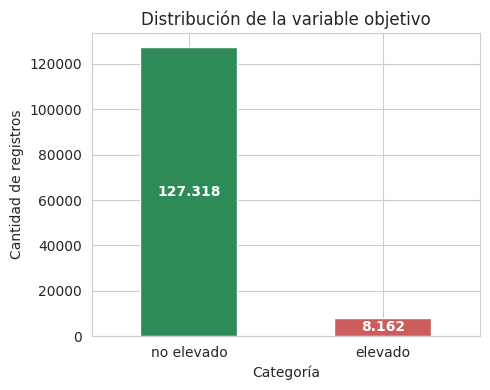

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))

calidad_aire["calidad_aire"].value_counts().plot(
    kind="bar",
    color=["seagreen", "indianred"],
    ax=ax
)

ax.set_title("Distribución de la variable objetivo")
ax.set_ylabel("Cantidad de registros")
ax.set_xlabel("Categoría")
ax.tick_params(axis="x", rotation=0)

# Agrego los valores dentro de las barras
ax.bar_label(
    ax.containers[0],
    labels=[
        f"{int(barra.get_height()):,}".replace(",", ".")
        for barra in ax.containers[0]
    ],
    label_type="center",
    color="white",
    fontsize=10,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

***Observación: desbalance de clases***

Identifico un desequilibrio importante en la variable objetivo: aproximadamente el 94 % de los registros clasificados corresponden a la categoría `no elevado`, mientras que el 6 % corresponde a `elevado`.

No aplico técnicas de balanceo en esta etapa, ya que todavía no comienzo el entrenamiento de los modelos. Sin embargo, tengo en cuenta este desequilibrio al definir las métricas de evaluación.

El *accuracy* podría resultar engañoso, porque un modelo podría clasificar correctamente la mayoría de los registros sin identificar adecuadamente los episodios de contaminación elevada. Por eso, también evaluaré *precision*, *recall*, F1-score y la matriz de confusión, prestando especial atención a la capacidad del modelo para detectar la clase `elevado`.

### 6.3 <u>Identificación de variables numéricas y categóricas</u>

Antes de definir las transformaciones, identifico las columnas candidatas según su tipo de dato.

Entre las variables temporales que construí, `estacion_anio` es categórica y no presenta un orden natural entre sus categorías (`verano`, `otoño`, `invierno` y `primavera`). Por este motivo, más adelante utilizaré *one-hot encoding* para convertirla en variables numéricas.

También tengo en cuenta que las transformaciones deben ajustarse únicamente con los datos de entrenamiento y aplicarse posteriormente a los datos de prueba, mediante un `Pipeline` de scikit-learn, para evitar la fuga de información (*data leakage*).

Mantengo la variable objetivo `calidad_aire` separada de las variables predictoras y definiré cuáles de ellas utilizaré teniendo en cuenta su relevancia y la posibilidad de evitar información que revele directamente el resultado que busco predecir.

In [ ]:
# Identifico columnas numéricas y categóricas dentro de las features candidatas
columnas_candidatas = ['CO_promedio', 'NO2_promedio', 'mes', 'dia_semana',
                        'HORA', 'es_fin_de_semana', 'estacion_anio']

df_candidatas = calidad_aire[columnas_candidatas]

columnas_numericas = df_candidatas.select_dtypes(include="number").columns.tolist()
columnas_categoricas = df_candidatas.select_dtypes(exclude="number").columns.tolist()

print("Columnas numéricas:", columnas_numericas)
print("Columnas categóricas:", columnas_categoricas)

Columnas numéricas: ['CO_promedio', 'NO2_promedio', 'mes', 'dia_semana', 'HORA', 'es_fin_de_semana']
Columnas categóricas: ['estacion_anio']


***Identificación de variables según su tipo***

Defino siete variables candidatas para el modelado, excluyendo las mediciones de PM10 que utilicé para construir la variable objetivo.

Identifico seis variables numéricas (`CO_promedio`, `NO2_promedio`, `mes`, `dia_semana`, `HORA` y `es_fin_de_semana`) y una variable categórica (`estacion_anio`).

Esta clasificación me permite preparar posteriormente las transformaciones correspondientes para cada tipo de variable dentro del proceso de modelado.

### 6.4. <u>Escalado de variables continuas</u>

**Nota:** Decido postergar el escalado hasta después de dividir el dataset en conjuntos de entrenamiento y prueba. Si calculo la media y la desviación estándar utilizando todos los registros antes de realizar la división, incorporaría información del conjunto de prueba al proceso de entrenamiento, provocando una posible fuga de información (*data leakage*).

Por eso, aplicaré el escalado únicamente a las variables numéricas que lo necesiten. Ajustaré el transformador con los datos de entrenamiento y utilizaré esos mismos parámetros para transformar los datos de prueba.

## 7. <u>Selección de variables (`X`) y variable objetivo (`y`)</u>

Para construir la matriz de variables predictoras `X`, excluyo `PM10_promedio` y las mediciones individuales de PM10 (`PM10_CENTENARIO`, `PM10_CORDOBA` y `PM10_LA_BOCA`).

Tomo esta decisión porque utilicé esas mediciones para calcular el promedio que define la variable objetivo `calidad_aire`. Si las incluyera entre las predictoras, el modelo recibiría información directamente relacionada con la regla utilizada para asignar las etiquetas, lo que generaría fuga de información (*data leakage*) y podría producir resultados artificialmente buenos.

De esta manera, utilizo como predictoras las mediciones promedio de CO y NO2 y las variables temporales, para evaluar si permiten identificar registros con concentraciones elevadas de PM10.

In [ ]:

# Excluir registros que no tienen una etiqueta confiable
calidad_aire = calidad_aire.dropna(subset=["calidad_aire"]).copy()

columnas_features = columnas_numericas + columnas_categoricas
X = calidad_aire[columnas_features]
y = calidad_aire["calidad_aire"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("\nDistribución final del objetivo:")
print(y.value_counts())


Dimensiones de X: (135480, 7)
Dimensiones de y: (135480,)

Distribución final del objetivo:
calidad_aire
no elevado    127318
elevado         8162
Name: count, dtype: int64


***Construcción de las matrices de entrenamiento***

Excluyo los registros que no tienen una categoría asignada en `calidad_aire`, ya que no dispongo de información suficiente para utilizarlos como ejemplos de entrenamiento.

Luego construyo `X` con las siete variables predictoras seleccionadas y `y` con la variable objetivo. Obtengo 135.480 registros para ambas estructuras, con sus índices alineados.

Conservo el desequilibrio original de las clases en esta etapa. Más adelante prepararé las variables y evaluaré los modelos teniendo en cuenta la menor representación de la categoría `elevado`.

**Justificación de las variables predictoras**

Selecciono siete variables predictoras para construir `X`:

- `CO_promedio` y `NO2_promedio`: representan los promedios de las mediciones disponibles de cada contaminante entre las estaciones. Considero que pueden aportar información relacionada con las emisiones y la actividad vehicular.
- `HORA`, `dia_semana` y `es_fin_de_semana`: permiten incorporar posibles variaciones asociadas con la actividad y el tránsito a lo largo del día y entre días laborables y fines de semana.
- `mes` y `estacion_anio`: permiten considerar posibles variaciones relacionadas con las condiciones climáticas y la época del año.

Decido no utilizar las columnas de CO y NO2 de cada estación por separado, sino resumir sus mediciones mediante los promedios `CO_promedio` y `NO2_promedio`. Esta decisión me permite sintetizar la información disponible, aunque reconozco que los promedios pueden ocultar diferencias geográficas entre estaciones y no garantizan por sí solos una mayor estabilidad frente a los valores faltantes.

Por otra parte, descarto las columnas correspondientes a Palermo durante la limpieza, porque superaban el umbral del 60 % de valores faltantes. En particular, `NO2_PALERMO` y `PM10_PALERMO` no contenían mediciones disponibles.

## 8. <u>División en conjuntos de Entrenamiento y Prueba (Train / Test) y preparación de variables</u>

Divido el dataset en dos conjuntos: entrenamiento (80 %) y prueba (20 %). Utilizo `train_test_split` y mantengo la proporción de las categorías mediante el parámetro `stratify`, para conservar la distribución de la variable objetivo en ambos conjuntos.

Después de realizar la división, preparo las transformaciones de las variables numéricas y categóricas mediante herramientas de scikit-learn. Ajusto los transformadores únicamente con los datos de entrenamiento y aplico las mismas transformaciones al conjunto de prueba, para evitar la fuga de información (*data leakage*).

Utilizo la estandarización para llevar las variables numéricas a una escala comparable, algo especialmente útil para modelos como Regresión Logística y KNN. En cambio, los modelos basados en árboles, como Random Forest, generalmente no necesitan escalado.

De esta manera, preparo los datos para comparar los distintos modelos bajo un procedimiento consistente.

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

assert len(X_train) + len(X_test) == len(X)
assert len(y_train) + len(y_test) == len(y)
print("\nDivisión correcta.")


X_train: (108384, 7)
X_test: (27096, 7)
y_train: (108384,)
y_test: (27096,)

División correcta.


***Resultado de la división Train / Test***

Divido los 135.480 registros en dos conjuntos: 108.384 para entrenamiento (80 %) y 27.096 para prueba (20 %).

Utilizo `stratify=y` para conservar una proporción similar de las categorías `no elevado` y `elevado` en ambos conjuntos, teniendo en cuenta el desequilibrio de clases identificado anteriormente.

Las comprobaciones confirman que la división se realizó correctamente y que mantengo la correspondencia entre las variables predictoras y la variable objetivo.

## <u>**Conclusiones preliminares - Pre Entrega**</u>

En esta primera parte trabajé sobre el dataset de calidad del aire de la Ciudad de Buenos Aires y lo preparé para la etapa de Machine Learning.

Primero exploré los datos e identifiqué distintos problemas, principalmente valores `s/d`, valores censurados como `<0.05`, datos faltantes y diferencias en el formato de las fechas.

Luego realicé la limpieza y transformación de los datos, preparé variables temporales y calculé promedios de CO y NO2 a partir de las mediciones disponibles en las estaciones. También definí `calidad_aire` como la variable objetivo del proyecto, utilizando el promedio de PM10 y un umbral operativo de 45 µg/m³ para distinguir entre las categorías `no elevado` y `elevado`.

Tuve especial cuidado con PM10, ya que utilizo sus mediciones para construir la variable objetivo. Por ese motivo, excluí `PM10_promedio` y las columnas individuales de PM10 de las variables predictoras, para evitar que el modelo reciba información directamente relacionada con la respuesta que debe clasificar.

Seleccioné siete variables predictoras: `CO_promedio`, `NO2_promedio`, `mes`, `dia_semana`, `HORA`, `es_fin_de_semana` y `estacion_anio`. Para prepararlas, definí el uso de *one-hot encoding* en la variable categórica y la estandarización de las variables numéricas que lo requieran. También contemplé la imputación de los valores faltantes dentro del proceso de modelado.

Por último, dividí los datos en conjuntos de entrenamiento y prueba, utilizando `stratify=y` para conservar una proporción similar de las clases en ambos conjuntos.

Con esta preparación, dejo el dataset listo para avanzar hacia el modelado, que desarrollo a partir de la sección 9. En esa etapa prestaré especial atención al desequilibrio de clases, a la selección de métricas adecuadas y a la prevención de fugas de información durante el entrenamiento y la evaluación.


## 9. <u>Preprocesamiento de variables</u>

Antes de entrenar los modelos, preparo las variables predictoras mediante un proceso de transformación que incluye el tratamiento de valores faltantes, la estandarización de variables numéricas y la codificación de variables categóricas.

Para las variables numéricas utilizo la mediana como estrategia de imputación y `StandardScaler` para estandarizar los valores. Para la variable categórica `estacion_anio`, utilizo la moda para completar posibles valores faltantes y `OneHotEncoder` para convertir sus categorías en variables binarias.

Integro estas transformaciones mediante `ColumnTransformer` y `Pipeline`. De esta manera, los parámetros de imputación, escalado y codificación se ajustan únicamente con los datos de entrenamiento, evitando la fuga de información durante la validación y evaluación de los modelos.

In [ ]:

# Preprocesamiento de variables numéricas
preprocesamiento_numerico = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Preprocesamiento de variables categóricas
preprocesamiento_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

# Combinación de transformaciones
preprocesamiento = ColumnTransformer([
    ("numericas", preprocesamiento_numerico, columnas_numericas),
    ("categoricas", preprocesamiento_categorico, columnas_categoricas)
])

print("Preprocesamiento definido correctamente.")

Preprocesamiento definido correctamente.


Defino dos procesos de preprocesamiento: uno para las variables numéricas y otro para las categóricas. En el primero, imputo los valores faltantes mediante la mediana y aplico la estandarización. En el segundo, utilizo la categoría más frecuente para completar faltantes y aplico codificación One-Hot.

Finalmente, integro ambos procesos mediante `ColumnTransformer`. Dejo las transformaciones preparadas para incorporarlas a cada modelo y ajustarlas durante el entrenamiento.

## 10. <u>Elección de los modelos</u>

Mi problema es de **clasificación binaria**: predecir si el nivel de PM10 se encuentra en la categoría `"no elevado"` o `"elevado"`. Como en la Pre-Entrega identifiqué un importante desbalance de clases, la categoría que más me interesa detectar es `"elevado"`, que defino como la clase positiva.

Voy a comparar tres modelos con enfoques diferentes:


| **Modelo** | **Por qué lo elijo** | **Cómo trato el desbalance** |
|---|---|---|
| **Regresión logística** | La utilizo como modelo de referencia (*baseline*). Es relativamente simple, rápida e interpretable. Sus coeficientes permiten analizar cómo se relacionan las variables predictoras con la probabilidad estimada de pertenecer a la clase `"elevado"`. | `class_weight="balanced"` |
| **Random Forest** | Puede capturar relaciones no lineales entre las variables y permite analizar la importancia de las variables predictoras. | `class_weight="balanced_subsample"` |
| **KNN** | Es un modelo basado en distancias que me permite comparar un enfoque diferente. Es sensible a la escala de las variables, por lo que requiere especial atención al escalado previo. | No dispone de un parámetro `class_weight` estándar. Utilizo `weights="distance"` para dar mayor influencia a los vecinos más cercanos, aunque esto no corrige directamente el desbalance entre clases. |



**Importante:** No utilizo K-Means porque es un algoritmo de aprendizaje no supervisado, mientras que mi problema es supervisado y ya tengo definida la variable objetivo.

Para evitar la fuga de información durante el preprocesamiento, utilizo un `Pipeline` que integra la imputación de valores faltantes, la codificación de variables categóricas, el escalado de las variables numéricas y el modelo correspondiente. De esta manera, cada transformación se ajusta únicamente con los datos de entrenamiento, incluso durante la validación cruzada.

Para comparar los resultados, presto especial atención al *recall* de la clase `"elevado"`, ya que me interesa identificar la mayor cantidad posible de registros con niveles elevados de PM10. También evalúo la precisión (*precision*), el F1 y la matriz de confusión. Complemento el análisis con métricas que permitan considerar el desequilibrio de clases.

In [ ]:


# Paso la variable objetivo a 0/1 (1 = "elevado"), así las métricas apuntan a la clase minoritaria
y_train_bin = (y_train == "elevado").astype(int)
y_test_bin = (y_test == "elevado").astype(int)

print("Proporción de 'elevado' en train:", round(y_train_bin.mean(), 4))
print("Proporción de 'elevado' en test: ", round(y_test_bin.mean(), 4))

modelos = {
    "Regresión logística": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                            class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=-1),
}

# Cada modelo queda dentro de un Pipeline: preprocesamiento (sección 9) + modelo
pipelines = {
    nombre: Pipeline([("prep", clone(preprocesamiento)), ("modelo", modelo)])
    for nombre, modelo in modelos.items()
}
print("Modelos a comparar:", list(pipelines.keys()))
print("Clases en y_train_bin:", np.unique(y_train_bin))
print("Clases en y_test_bin:", np.unique(y_test_bin))

Proporción de 'elevado' en train: 0.0602
Proporción de 'elevado' en test:  0.0602
Modelos a comparar: ['Regresión logística', 'Random Forest', 'KNN']
Clases en y_train_bin: [0 1]
Clases en y_test_bin: [0 1]


Defino tres modelos de clasificación: Regresión Logística, Random Forest y KNN. Configuro pesos de clase para los dos primeros, con el objetivo de compensar el desequilibrio de la variable objetivo.

También convierto temporalmente la categoría `"elevado"` en 1 y `"no elevado"` en 0 para facilitar el cálculo de algunas métricas binarias.

Finalmente, integro cada modelo con una copia independiente del preprocesamiento mediante `Pipeline`. Compruebo que los tres modelos estén definidos y que la proporción de la clase minoritaria sea del 6,02 % tanto en entrenamiento como en prueba.

## 11. <u>Entrenamiento</u>



In [ ]:
for nombre, pipe in pipelines.items():
    inicio = time.time()
    pipe.fit(X_train, y_train_bin)
    print(f"{nombre}: entrenado en {time.time() - inicio:.1f} segundos")

Regresión logística: entrenado en 1.0 segundos
Random Forest: entrenado en 19.7 segundos
KNN: entrenado en 0.4 segundos




Entreno cada modelo con un `Pipeline` utilizando el conjunto de entrenamiento (`X_train` e `y_train_bin`). Al estar encapsulados, los pipelines ajustan el imputador, el escalador (`StandardScaler`) y el codificador (`OneHotEncoder`) únicamente con los datos de entrenamiento. Posteriormente, aplican las transformaciones aprendidas a los nuevos datos sin volver a ajustarlas. Esto evita la filtración de información durante el preprocesamiento.

También tengo en cuenta que pueden existir otras fuentes de fuga de información originadas en etapas anteriores de la preparación de los datos, por lo que debo considerarlas al interpretar los resultados.

**Tiempos de ejecución registrados durante el entrenamiento:**

- **Regresión Logística:** aproximadamente 1,0 segundos. Su ajuste fue muy rápido.
- **Random Forest:** aproximadamente 19,7 segundos. Fue el modelo que más tiempo requirió, debido a la construcción de 100 árboles de decisión.
- **KNN (k-Nearest Neighbors):** aproximadamente 0,4 segundos. Al ser un método de aprendizaje *perezoso*, el entrenamiento consiste principalmente en almacenar las observaciones. Una parte importante del costo computacional se traslada a la etapa de predicción.

## 12. <u>Evaluación en el conjunto de prueba</u>

#### Justificación de las métricas seleccionadas frente al desbalance de clases

Cuando existe un desbalance importante entre las clases, un modelo que clasifique todos los registros como `"no elevado"` puede obtener un *Accuracy* elevado sin detectar ningún caso de calidad del aire `"elevado"`. Por eso, no utilizo el *Accuracy* como métrica principal y me enfoco en las métricas específicas de la clase minoritaria (`1` = `"elevado"`).

- **Precision (clase `"elevado"`):** de todos los registros que el modelo clasifica como `"elevado"`, ¿cuántos pertenecían realmente a esa clase?
- **Recall / Sensibilidad (clase `"elevado"`):** de todos los registros que realmente pertenecían a la clase `"elevado"`, ¿cuántos logró detectar el modelo? Es importante si el objetivo es reducir los falsos negativos, es decir, los casos de calidad del aire `"elevado"` que el modelo no identifica.
- **F1-Score (clase `"elevado"`):** media armónica entre *Precision* y *Recall*. Permite comparar el equilibrio entre ambas métricas.
- **PR-AUC (área bajo la curva Precision-Recall):** resume la relación entre precisión y recall a distintos umbrales de decisión. Resulta especialmente útil cuando interesa evaluar la detección de la clase minoritaria.

In [ ]:


resultados = []
predicciones = {}
probabilidades = {}

for nombre, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    predicciones[nombre] = y_pred
    probabilidades[nombre] = y_prob

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test_bin, y_pred),
        "Precision (elevado)": precision_score(y_test_bin, y_pred, zero_division=0),
        "Recall (elevado)": recall_score(y_test_bin, y_pred),
        "F1 (elevado)": f1_score(y_test_bin, y_pred),
        "PR-AUC": average_precision_score(y_test_bin, y_prob),
        "ROC-AUC": roc_auc_score(y_test_bin, y_prob),
    })

tabla_test = pd.DataFrame(resultados).set_index("Modelo").round(3)
tabla_test

,Accuracy,Precision (elevado),Recall (elevado),F1 (elevado),PR-AUC,ROC-AUC
Modelo,,,,,,
Regresión logística,0.692,0.107,0.562,0.180,0.147,0.671
Random Forest,0.926,0.369,0.329,0.348,0.321,0.836
KNN,0.940,0.494,0.071,0.124,0.242,0.798


Una vez entrenados los *pipelines*, evalúo su capacidad de generalización sobre el conjunto de prueba (`X_test`, compuesto por 27.096 registros), que no se utilizó para ajustar los modelos.

Calculo las métricas clave, centradas en la clase positiva (`1` = `"elevado"`), y genero las matrices de confusión para analizar en detalle la distribución de aciertos y errores de cada modelo. De esta manera, puedo comparar su capacidad para identificar los registros de clase `"elevado"` y detectar los casos que clasifican incorrectamente.

In [ ]:
for nombre, y_pred in predicciones.items():
    print("=" * 60)
    print(nombre)
    print(classification_report(y_test_bin, y_pred, target_names=["no elevado", "elevado"], zero_division=0))

Regresión logística
              precision    recall  f1-score   support

  no elevado       0.96      0.70      0.81     25464
     elevado       0.11      0.56      0.18      1632

    accuracy                           0.69     27096
   macro avg       0.53      0.63      0.49     27096
weighted avg       0.91      0.69      0.77     27096

Random Forest
              precision    recall  f1-score   support

  no elevado       0.96      0.96      0.96     25464
     elevado       0.37      0.33      0.35      1632

    accuracy                           0.93     27096
   macro avg       0.66      0.65      0.65     27096
weighted avg       0.92      0.93      0.92     27096

KNN
              precision    recall  f1-score   support

  no elevado       0.94      1.00      0.97     25464
     elevado       0.49      0.07      0.12      1632

    accuracy                           0.94     27096
   macro avg       0.72      0.53      0.55     27096
weighted avg       0.92      0.94   

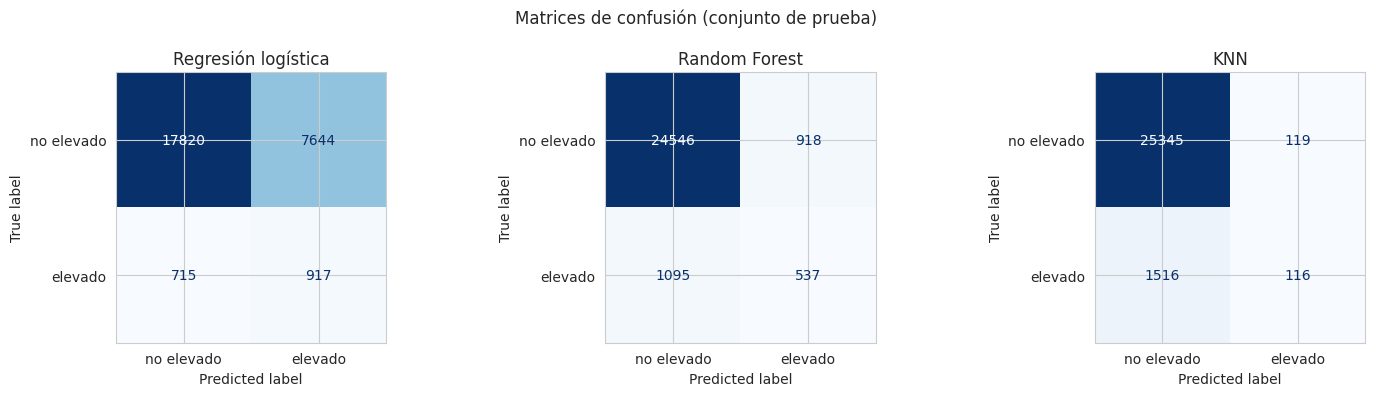

In [ ]:
# Matrices de confusión
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, y_pred) in zip(ejes, predicciones.items()):
    cm = confusion_matrix(y_test_bin, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["no elevado", "elevado"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre)
plt.suptitle("Matrices de confusión (conjunto de prueba)")
plt.tight_layout()
plt.show()

#### Observaciones de la evaluación en el conjunto de prueba

1. **Limitaciones del Accuracy como criterio de decisión:**
   - KNN obtiene el *Accuracy* más elevado (0,940). Sin embargo, su *Recall* para la clase `"elevado"` es de apenas 0,071 (7,1 %), por lo que identifica una proporción muy reducida de los registros que realmente pertenecen a esa clase. Esto demuestra que un *Accuracy* elevado no garantiza una buena detección de los casos de interés.

2. **Comportamiento de la Regresión Logística (`class_weight="balanced"`):**
   - Registra el mayor *Recall* de los tres modelos (0,562 / 56,2 %), lo que significa que detecta más de la mitad de los registros reales de clase `"elevado"`. No obstante, su *Precision* es de solo 0,107 (10,7 %), lo que indica una cantidad importante de falsas alarmas.

3. **Random Forest como modelo de mejor equilibrio global:**
   - Obtiene el mayor **F1-Score para la clase `"elevado"` (0,348)** y el mayor **PR-AUC (0,321)**. Además, presenta un **ROC-AUC de 0,836**, el más alto de los tres modelos. Su *Precision* es de 0,369 y su *Recall* de 0,329. En conjunto, estos resultados lo convierten en el candidato más equilibrado de los tres modelos evaluados.
   - Sin embargo, su *Recall* indica que todavía no detecta aproximadamente el 67 % de los registros reales de clase `"elevado"`. Por lo tanto, su desempeño puede mejorarse si busco priorizar la detección de estos casos.

## 13. <u>Validación cruzada</u>

El resultado obtenido sobre un único conjunto de prueba puede depender de cómo se realizó la división aleatoria (*split*). Para estimar el rendimiento de los modelos de forma más robusta y evaluar su estabilidad, ejecuto una **validación cruzada estratificada de 5 pliegues (`StratifiedKFold`) sobre el conjunto de entrenamiento (`X_train`)**.

`StratifiedKFold` mantiene aproximadamente la proporción de las clases `"no elevado"` y `"elevado"` en cada uno de los 5 pliegues. Al utilizar los `Pipeline` creados en la sección anterior, la imputación, la estandarización (`StandardScaler`) y la codificación *One-Hot* (`OneHotEncoder`) se ajustan de manera independiente dentro de cada pliegue. Esto evita la filtración de información durante el preprocesamiento entre los subconjuntos de entrenamiento y validación de cada *fold*.

In [ ]:


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas_cv = {"precision": "precision", "recall": "recall", "f1": "f1", "pr_auc": "average_precision"}

filas_cv = []
for nombre, pipe in pipelines.items():
    inicio = time.time()
    res = cross_validate(pipe, X_train, y_train_bin, cv=cv, scoring=metricas_cv, n_jobs=1)
    fila = {"Modelo": nombre}
    for m in metricas_cv:
        fila[f"{m} (media)"] = res[f"test_{m}"].mean()
        fila[f"{m} (desvío)"] = res[f"test_{m}"].std()
    filas_cv.append(fila)
    print(f"{nombre}: validación cruzada lista en {time.time() - inicio:.1f} s")

tabla_cv = pd.DataFrame(filas_cv).set_index("Modelo").round(3)
tabla_cv

Regresión logística: validación cruzada lista en 2.7 s
Random Forest: validación cruzada lista en 58.9 s
KNN: validación cruzada lista en 30.4 s


,precision (media),precision (desvío),recall (media),recall (desvío),f1 (media),f1 (desvío),pr_auc (media),pr_auc (desvío)
Modelo,,,,,,,,
Regresión logística,0.109,0.001,0.574,0.006,0.183,0.001,0.158,0.004
Random Forest,0.363,0.008,0.326,0.006,0.343,0.006,0.328,0.006
KNN,0.585,0.038,0.081,0.006,0.142,0.010,0.260,0.011


### Observaciones

1. **Coherencia y estabilidad general**

   Los resultados de la validación cruzada muestran que **Random Forest obtiene el mejor rendimiento general**, con un F1 medio de **0,343**, seguido por la Regresión Logística (**0,183**) y KNN (**0,142**). Los desvíos estándar del F1 son reducidos: 0,006 para Random Forest, 0,001 para la Regresión Logística y 0,010 para KNN. Esto indica que las métricas se mantienen relativamente estables entre los cinco pliegues de validación.

2. **Comparación entre validación cruzada y conjunto de prueba**

   Random Forest presenta una Precision media de **0,363**, un Recall medio de **0,326** y un F1 medio de **0,343** en validación cruzada. En el conjunto de prueba, los valores fueron 0,369 de Precision, 0,329 de Recall y 0,348 de F1. La similitud entre ambos resultados sugiere que el rendimiento del modelo es relativamente consistente en estas evaluaciones.

3. **Análisis del PR-AUC**

   Random Forest alcanza un PR-AUC medio de **0,328**, con un desvío estándar de 0,006, mientras que en el conjunto de prueba obtiene **0,321**. Estos valores son superiores a los de KNN (0,260 en validación cruzada) y la Regresión Logística (0,158). Esto indica que Random Forest presenta una mejor capacidad para mantener una relación favorable entre Precision y Recall a distintos umbrales de decisión, algo especialmente relevante debido al desbalance de clases.

En conjunto, los resultados respaldan la selección de **Random Forest como modelo candidato principal**. Sin embargo, esta conclusión queda sujeta a la revisión de la construcción de la variable objetivo, la calidad de los datos utilizados y las limitaciones de la validación aleatoria en un conjunto de datos con dimensión temporal.

## 14. <u>Visualización de resultados e interpretación</u>

### 14.1 <u>Comparación de modelos</u>

Grafico la comparación del **F1-Score** y del **Recall** para la clase `"elevado"` entre el conjunto de prueba (*test*) y la validación cruzada (*CV*).

El F1-Score me permite comparar el equilibrio entre Precision y Recall, mientras que el Recall muestra qué proporción de los registros realmente elevados logra identificar cada modelo.

Esta comparación me permite observar si el rendimiento obtenido en el conjunto de prueba se mantiene durante la validación cruzada y analizar la consistencia de los modelos en ambas evaluaciones.

Además, utilizo las **curvas Precision-Recall** para analizar cómo varían la precisión y el Recall al modificar el umbral de decisión de cada modelo.

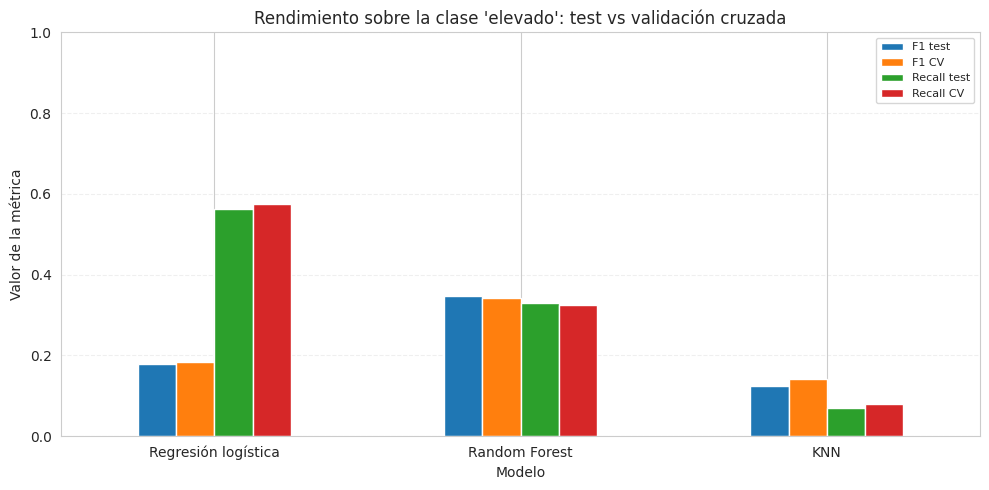

In [ ]:

# Comparación F1 y Recall: test vs validación cruzada

comparacion = pd.DataFrame({
    "F1 test": tabla_test["F1 (elevado)"],
    "F1 CV": tabla_cv["f1 (media)"],
    "Recall test": tabla_test["Recall (elevado)"],
    "Recall CV": tabla_cv["recall (media)"],
})

ax = comparacion.plot(kind="bar", figsize=(10, 5), rot=0)

ax.set_title("Rendimiento sobre la clase 'elevado': test vs validación cruzada")
ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0, 1)
ax.legend(loc="upper right", fontsize=8)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



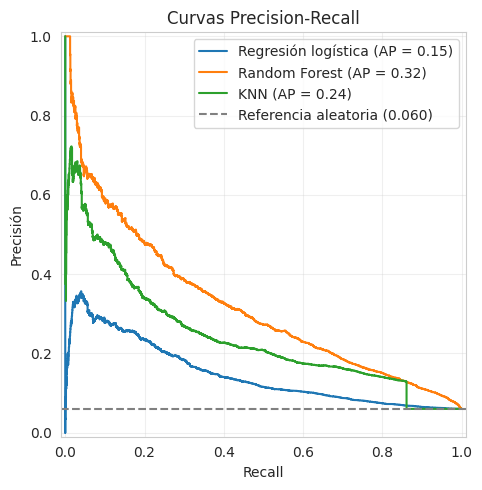

In [ ]:

# Curvas Precision-Recall
fig, ax = plt.subplots(figsize=(7, 5))

for nombre, y_prob in probabilidades.items():
    PrecisionRecallDisplay.from_predictions(
        y_test_bin,
        y_prob,
        name=nombre,
        ax=ax
    )

# Línea de referencia: proporción de la clase positiva
ax.axhline(
    y=y_test_bin.mean(),
    color="gray",
    linestyle="--",
    label=f"Referencia aleatoria ({y_test_bin.mean():.3f})"
)

ax.set_title("Curvas Precision-Recall")
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


***Interpretación de las curvas Precision-Recall***

Las curvas Precision-Recall permiten comparar la capacidad de los modelos para identificar registros de PM10 elevado a distintos umbrales de decisión.

Observo que Random Forest presenta un mejor comportamiento general, en concordancia con su mayor PR-AUC obtenido durante la evaluación. Esto indica que mantiene una relación más favorable entre Precision y Recall a lo largo de los distintos umbrales.

La Regresión Logística muestra una mayor capacidad para recuperar casos elevados, aunque esto implica una menor precisión y, por lo tanto, más falsas alarmas.

Por su parte, KNN presenta una capacidad de detección más limitada, lo que coincide con su bajo Recall en la evaluación del conjunto de prueba.

La línea de referencia representa la proporción de registros elevados en el conjunto de prueba. Permite comparar el comportamiento de los modelos con una referencia aleatoria.

### Observaciones

- **Consistencia entre Test y CV:** Para cada modelo, el F1-Score y el Recall obtenidos en la validación cruzada son relativamente cercanos a los del conjunto de prueba. En **Random Forest**, el F1 es de **0,343 en CV** frente a **0,348 en test**, mientras que el Recall es de **0,326 en CV** frente a **0,329 en test**. Esta similitud sugiere que el rendimiento se mantiene relativamente estable entre ambas evaluaciones.

- **Balance de desempeño:** **Random Forest** obtiene el mejor F1 en ambas evaluaciones. La **Regresión Logística** presenta el mayor Recall en test (**0,562**) y en validación cruzada (**0,574**), pero a costa de una precisión baja (**0,107 en test** y **0,109 en CV**). Por su parte, KNN alcanza una precisión de **0,494 en test** y **0,585 en CV**, pero su Recall es de apenas **0,071 en test** y **0,081 en CV**, por lo que identifica una proporción reducida de los registros de la clase `"elevado"`.

- **Curvas Precision-Recall:** Según las métricas obtenidas, **Random Forest** presenta el mayor PR-AUC en test (**0,321**) y en validación cruzada (**0,328**), seguido por KNN (**0,242 en test** y **0,260 en CV**) y la Regresión Logística (**0,147 en test** y **0,158 en CV**). Esto indica que Random Forest ofrece la mejor capacidad global para equilibrar Precision y Recall a través de distintos umbrales de decisión.

- **Comparación con la línea base:** La línea de referencia de las curvas Precision-Recall corresponde a la proporción de registros de la clase `"elevado"` en el conjunto de prueba. Su valor es aproximadamente **0,060 (6 %)**. Los tres modelos presentan valores de PR-AUC superiores a esta referencia, aunque Random Forest muestra el mejor resultado.

### 14.2 <u>¿Qué variables usa el modelo?</u>

Analizo la importancia de las características del modelo **Random Forest**, calculada a partir de la reducción de impureza de Gini, y los coeficientes de la **Regresión Logística** para interpretar qué variables contribuyen más a las predicciones y qué dirección tienen sus asociaciones con la clase `"elevado"`.

Ambos enfoques ofrecen perspectivas complementarias: Random Forest permite identificar las variables que más contribuyen a sus predicciones, mientras que los coeficientes de la Regresión Logística permiten analizar la dirección de la asociación estimada entre cada característica y la probabilidad de pertenecer a la clase `"elevado"`. Estas relaciones no implican causalidad.

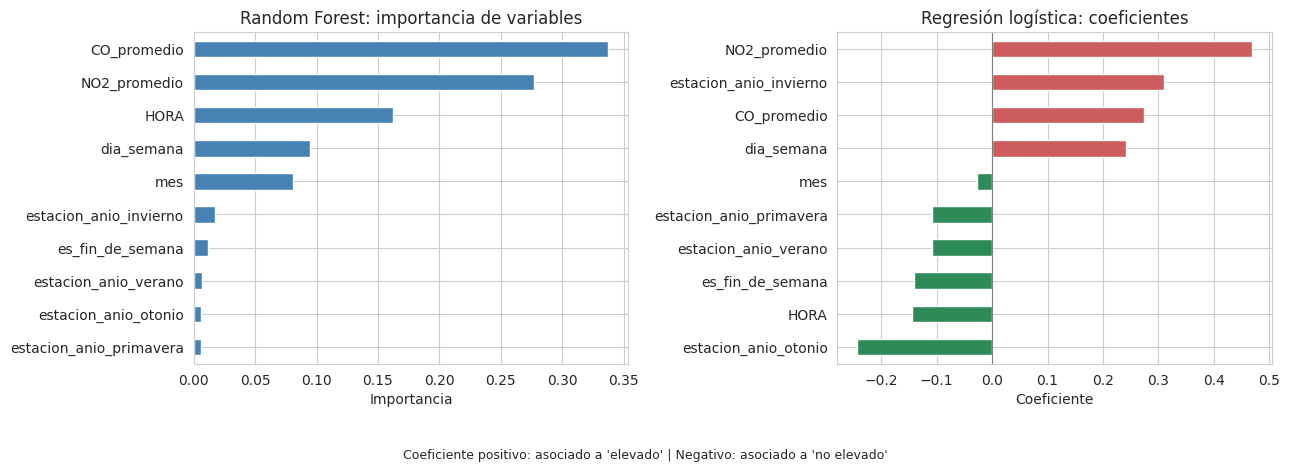

In [ ]:


# Importancia de variables: Random Forest y Regresión Logística

# Random Forest
prep_rf = pipelines["Random Forest"].named_steps["prep"]
nombres_rf = prep_rf.get_feature_names_out()
nombres_rf = [n.split("__", 1)[1] for n in nombres_rf]

importancias = pd.Series(
    pipelines["Random Forest"].named_steps["modelo"].feature_importances_,
    index=nombres_rf
).sort_values()

# Regresión Logística
prep_lr = pipelines["Regresión logística"].named_steps["prep"]
nombres_lr = prep_lr.get_feature_names_out()
nombres_lr = [n.split("__", 1)[1] for n in nombres_lr]

coeficientes = pd.Series(
    pipelines["Regresión logística"].named_steps["modelo"].coef_[0],
    index=nombres_lr
).sort_values()

# Gráficos
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

importancias.plot(kind="barh", ax=ejes[0], color="steelblue")
ejes[0].set_title("Random Forest: importancia de variables")
ejes[0].set_xlabel("Importancia")

coeficientes.plot(
    kind="barh",
    ax=ejes[1],
    color=["indianred" if c > 0 else "seagreen" for c in coeficientes]
)
ejes[1].set_title("Regresión logística: coeficientes")
ejes[1].set_xlabel("Coeficiente")
ejes[1].axvline(0, color="gray", linewidth=0.8)

fig.text(
    0.5, -0.03,
    "Coeficiente positivo: asociado a 'elevado' | Negativo: asociado a 'no elevado'",
    ha="center",
    fontsize=9
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.18)
plt.show()


***Observaciones de las variables utilizadas***

- **Predictores dominantes:** En **Random Forest**, los promedios de contaminantes gaseosos (`CO_promedio` y `NO2_promedio`) aparecen entre los predictores más relevantes, seguidos por variables temporales como `HORA`, `dia_semana` y `mes`. Esta importancia indica cuánto contribuyen las variables a las predicciones del modelo, pero no demuestra por sí sola una relación causal con la contaminación elevada.

- **Direccionalidad del modelo lineal:** Los coeficientes de la **Regresión Logística** permiten analizar la dirección de la asociación estimada entre cada variable y la clase `"elevado"`. Los coeficientes positivos indican una asociación con mayores *log-odds* de pertenecer a esa clase, mientras que los negativos indican una asociación con menores *log-odds*. En el caso de las variables estacionales, la interpretación se realiza en relación con la categoría de referencia que utiliza el modelo. Estas asociaciones no implican causalidad.

### 14.3 <u>Análisis de errores del mejor modelo</u>

Selecciono **Random Forest** como modelo candidato principal, ya que obtuvo el mayor F1 medio para la clase `"elevado"` en la validación cruzada (**0,343**). Para profundizar en su rendimiento, analizo los errores de clasificación mediante el **Recall de la clase `"elevado"`**, desagregado por estación del año y por hora del día.

Este análisis permite identificar en qué períodos el modelo detecta una mayor proporción de los registros que realmente presentan niveles elevados de PM10 y en cuáles tiene más dificultades para identificarlos. De esta manera, puedo evaluar si su capacidad de detección varía según las condiciones temporales.

Mejor modelo según F1 en validación cruzada: Random Forest
tipo
Acierto 'no elevado'    24546
Falso negativo           1095
Falso positivo            918
Acierto 'elevado'         537
Name: count, dtype: int64

Recall por estación del año:
estacion_anio
invierno     0.474
otonio       0.253
primavera    0.193
verano       0.235
Name: pred, dtype: float64


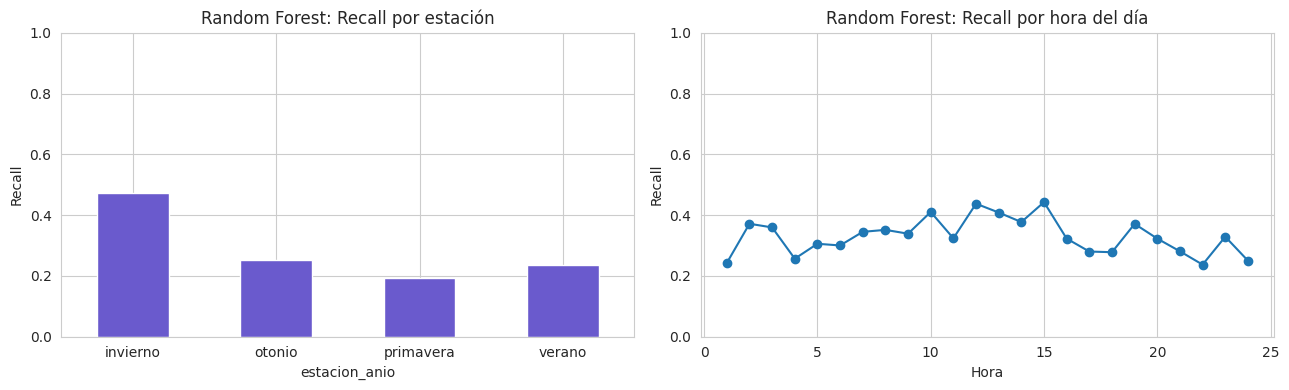

In [ ]:

mejor_modelo = tabla_cv["f1 (media)"].idxmax()
print("Mejor modelo según F1 en validación cruzada:", mejor_modelo)

errores = X_test.copy()
errores["real"] = y_test_bin.values
errores["pred"] = predicciones[mejor_modelo]

errores["tipo"] = np.select(
    [(errores.real == 1) & (errores.pred == 1),
     (errores.real == 0) & (errores.pred == 1),
     (errores.real == 1) & (errores.pred == 0)],
    ["Acierto 'elevado'", "Falso positivo", "Falso negativo"],
    default="Acierto 'no elevado'"
)

print(errores["tipo"].value_counts())

# Recall por estación del año (solo casos realmente elevados)
reales_elevados = errores[errores.real == 1]
recall_estacion = reales_elevados.groupby("estacion_anio")["pred"].mean().round(3)

print("\nRecall por estación del año:")
print(recall_estacion)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

recall_estacion.plot(kind="bar", ax=ejes[0], color="slateblue", rot=0)
ejes[0].set_title(f"{mejor_modelo}: Recall por estación")
ejes[0].set_ylabel("Recall")
ejes[0].set_ylim(0, 1)

recall_hora = reales_elevados.groupby("HORA")["pred"].mean()
ejes[1].plot(recall_hora.index, recall_hora.values, marker="o")
ejes[1].set_title(f"{mejor_modelo}: Recall por hora del día")
ejes[1].set_xlabel("Hora")
ejes[1].set_ylabel("Recall")
ejes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()


***Observaciones sobre los errores de clasificación***

- **Aciertos y errores:** Random Forest clasificó correctamente 24.546 registros como `"no elevado"` y detectó 537 registros realmente `"elevado"`. Sin embargo, presentó 918 falsos positivos y 1.095 falsos negativos. Estos últimos representan casos de contaminación elevada que el modelo no logró identificar.

- **Detección por estación del año:** El mayor Recall se observa durante el invierno (**0,474**), lo que indica que el modelo detectó aproximadamente la mitad de los registros realmente elevados de esa estación. Le siguen el otoño (**0,253**), el verano (**0,235**) y la primavera (**0,193**).

- **Diferencias temporales:** Los resultados muestran que la capacidad de detección del modelo varía según la estación del año. Sin embargo, estos valores describen su rendimiento sobre el conjunto de prueba y no demuestran que la estación sea la causa de esas diferencias.

In [ ]:
reales_elevados["estacion_anio"].value_counts()

,count
estacion_anio,
invierno,673
otonio,348
primavera,326
verano,285


***Cantidad de casos por estación:***
 El análisis contempla 1.632 registros realmente elevados. El invierno concentra la mayor cantidad (673), seguido de otoño (348), primavera (326) y verano (285). Por lo tanto, las diferencias de Recall se observan sobre grupos de distinto tamaño, aunque todos cuentan con una cantidad de casos suficiente para realizar una comparación descriptiva.

In [ ]:

# Distribución de casos "elevado" por estación en train y test

elevado_train = X_train.loc[y_train_bin == 1, "estacion_anio"]
elevado_test = X_test.loc[y_test_bin == 1, "estacion_anio"]

dist_estaciones = pd.DataFrame({
    "Casos elevados train": elevado_train.value_counts(),
    "% del total elevado train": (
        elevado_train.value_counts(normalize=True) * 100
    ).round(1),
    "Casos elevados test": elevado_test.value_counts(),
    "% del total elevado test": (
        elevado_test.value_counts(normalize=True) * 100
    ).round(1),
})

# Porcentaje de registros elevados dentro de cada estación
dist_estaciones["% elevado dentro de estación (train)"] = (
    elevado_train.value_counts()
    / X_train["estacion_anio"].value_counts()
    * 100
).round(2)

dist_estaciones["% elevado dentro de estación (test)"] = (
    elevado_test.value_counts()
    / X_test["estacion_anio"].value_counts()
    * 100
).round(2)

dist_estaciones



,Casos elevados train,% del total elevado train,Casos elevados test,% del total elevado test,% elevado dentro de estación (train),% elevado dentro de estación (test)
estacion_anio,,,,,,
invierno,2818,43.2,673,41.2,10.02,9.79
otonio,1306,20.0,348,21.3,4.71,4.91
primavera,1318,20.2,326,20.0,4.97,4.94
verano,1088,16.7,285,17.5,4.19,4.36


 ***Distribución de casos elevados por estación***

La comparación entre los conjuntos de entrenamiento y prueba muestra una distribución similar de los registros elevados en las cuatro estaciones. El invierno concentra la mayor proporción de casos positivos (43,2 % en train y 41,2 % en test), mientras que el verano presenta la menor (16,7 % y 17,5 %, respectivamente).

Al analizar la proporción de casos elevados dentro de cada estación, observo que el invierno también presenta la mayor frecuencia, cercana al 10 %. En cambio, durante el verano esta proporción se encuentra alrededor del 4,2 % en train y 4,4 % en test.

Esta distribución permite contextualizar las diferencias de Recall observadas anteriormente y confirma que los conjuntos de entrenamiento y prueba mantienen proporciones estacionales comparables. Sin embargo, la mayor frecuencia de casos elevados en invierno no explica por sí sola el mejor rendimiento del modelo en esa estación.

## 15. <u>Ajuste de hiperparámetros (GridSearchCV)</u>

Hasta ahora utilicé Random Forest con parámetros elegidos manualmente. Con `GridSearchCV` pruebo sistemáticamente distintas combinaciones de hiperparámetros y selecciono la que obtiene el mejor F1 promedio mediante validación cruzada sobre el conjunto de **entrenamiento**.

Utilizo F1 porque busco un equilibrio entre *precision* y *recall* para la clase positiva `"elevado"` (codificada como 1). La precisión indica qué proporción de las predicciones positivas corresponde a casos realmente elevados, mientras que el recall indica qué proporción de los casos realmente elevados logra detectar el modelo.

**Parámetros que pruebo:**

- `n_estimators` (cantidad de árboles): 100 o 200.
- `max_depth` (profundidad máxima): sin límite (`None`) o 20. Limitar la profundidad puede ayudar a reducir el sobreajuste.
- `min_samples_leaf` (mínimo de muestras por hoja): 1, 5 o 10. Los valores más altos pueden generar árboles menos complejos.

En total, evalúo 12 combinaciones mediante 3 folds de validación cruzada, lo que representa 36 entrenamientos durante la búsqueda. Utilizo 3 folds para reducir el tiempo de ejecución.

**Importante:** el conjunto de prueba no participa en la búsqueda de hiperparámetros. Se reserva para evaluar el rendimiento del modelo seleccionado, evitando utilizarlo para tomar decisiones durante el ajuste. Una vez identificada la mejor combinación, GridSearchCV vuelve a entrenar el modelo con todo el conjunto de entrenamiento.

In [ ]:


pipe_rf = Pipeline([
    ("prep", clone(preprocesamiento)),
    ("modelo", RandomForestClassifier(class_weight="balanced_subsample",
                                      n_jobs=-1, random_state=42))
])

param_grid = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [None, 20],
    "modelo__min_samples_leaf": [1, 5, 10],
}

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

inicio = time.time()
busqueda = GridSearchCV(pipe_rf, param_grid, scoring="f1", cv=cv3,
                        n_jobs=1, verbose=1)
busqueda.fit(X_train, y_train_bin)
print(f"Búsqueda terminada en {(time.time() - inicio) / 60:.1f} minutos")

print("Mejores parámetros:", busqueda.best_params_)
print("Mejor F1 en CV:", round(busqueda.best_score_, 3))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Búsqueda terminada en 10.9 minutos
Mejores parámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
Mejor F1 en CV: 0.341


***Resultados de la búsqueda de hiperparámetros***


La búsqueda mediante `GridSearchCV` seleccionó una configuración con 200 árboles (`n_estimators=200`), sin límite de profundidad (`max_depth=None`) y con un mínimo de 5 muestras por hoja (`min_samples_leaf=5`). Su F1 medio en validación cruzada (3 pliegues) fue de 0,341.

Para compararlo en igualdad de condiciones, uso la configuración del Random Forest original (100 árboles, `max_depth=None`, `min_samples_leaf=5`), que en esta misma búsqueda obtuvo 0,338. La mejora es de aproximadamente 0,003, una diferencia menor que el desvío entre pliegues (alrededor de 0,006), por lo que no la considero relevante.

*Nota:* no comparo con el F1 de 0,343 de la sección 13, porque esa validación usó 5 pliegues y esta 3, por lo que los valores no son directamente comparables.

La búsqueda identificó una configuración alternativa, pero será necesario evaluar su comportamiento sobre el conjunto de prueba antes de decidir si conviene reemplazar el modelo inicial.

In [ ]:
resultados_gs = pd.DataFrame(busqueda.cv_results_)[[
    "param_modelo__n_estimators", "param_modelo__max_depth",
    "param_modelo__min_samples_leaf", "mean_test_score",
    "std_test_score", "rank_test_score"
]].sort_values("rank_test_score").round(3)

resultados_gs.columns = ["n_estimators", "max_depth", "min_samples_leaf",
                         "F1 medio (CV)", "Desvío", "Ranking"]
resultados_gs

,n_estimators,max_depth,min_samples_leaf,F1 medio (CV),Desvío,Ranking
3,200,None,5,0.341,0.006,1
9,200,20,5,0.339,0.003,2
2,100,None,5,0.338,0.006,3
5,200,None,10,0.337,0.005,4
4,100,None,10,0.337,0.007,5
11,200,20,10,0.336,0.008,6
10,100,20,10,0.335,0.007,7
8,100,20,5,0.335,0.003,8
7,200,20,1,0.215,0.005,9
6,100,20,1,0.212,0.004,10


***Análisis de las combinaciones evaluadas***


La tabla muestra que las ocho mejores configuraciones usan `min_samples_leaf` de 5 o 10, con valores de F1 entre 0,335 y 0,341. La mejor combinación utiliza 200 árboles, profundidad sin límite y 5 muestras mínimas por hoja, con un F1 medio de 0,341.

La cantidad mínima de muestras por hoja es el hiperparámetro con mayor influencia: con `min_samples_leaf=1` el F1 cae a valores entre 0,18 y 0,22, mientras que con 5 o 10 se mantiene alrededor de 0,34. Pasar de 100 a 200 árboles produce mejoras muy pequeñas, y limitar la profundidad a 20 tampoco mejora las configuraciones mejor posicionadas.

En conjunto, los resultados sugieren que exigir hojas con más observaciones favorece el rendimiento en esta búsqueda, y que las diferencias entre las mejores configuraciones son pequeñas.

In [ ]:
mejor_rf = busqueda.best_estimator_
y_pred_gs = mejor_rf.predict(X_test)
y_prob_gs = mejor_rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test_bin, y_pred_gs,
                            target_names=["no elevado", "elevado"], zero_division=0))

comparacion_gs = pd.DataFrame({
    "Random Forest original": tabla_test.loc["Random Forest"],
    "Random Forest ajustado": {
        "Accuracy": accuracy_score(y_test_bin, y_pred_gs),
        "Precision (elevado)": precision_score(y_test_bin, y_pred_gs, zero_division=0),
        "Recall (elevado)": recall_score(y_test_bin, y_pred_gs),
        "F1 (elevado)": f1_score(y_test_bin, y_pred_gs),
        "PR-AUC": average_precision_score(y_test_bin, y_prob_gs),
        "ROC-AUC": roc_auc_score(y_test_bin, y_prob_gs),
    }
}).round(3)
comparacion_gs

              precision    recall  f1-score   support

  no elevado       0.96      0.96      0.96     25464
     elevado       0.37      0.33      0.35      1632

    accuracy                           0.93     27096
   macro avg       0.66      0.65      0.65     27096
weighted avg       0.92      0.93      0.92     27096



,Random Forest original,Random Forest ajustado
Accuracy,0.926,0.926
Precision (elevado),0.369,0.373
Recall (elevado),0.329,0.326
F1 (elevado),0.348,0.348
PR-AUC,0.321,0.323
ROC-AUC,0.836,0.838


### Evaluación del Random Forest ajustado

Al evaluar el modelo obtenido mediante `GridSearchCV` sobre el conjunto de prueba, observo que es prácticamente idéntico al Random Forest original:

- Precision (clase "elevado"): 0,373 frente a 0,369.
- Recall (clase "elevado"): 0,326 frente a 0,329.
- F1 (clase "elevado"): 0,348 en ambos modelos.
- PR-AUC: 0,323 frente a 0,321.
- ROC-AUC: 0,838 frente a 0,836.
- Accuracy: 0,926 en ambos.

Las diferencias son de milésimas, por lo que el ajuste no produce un cambio en el comportamiento del modelo ni un equilibrio distinto entre precisión y recall.

**Observaciones del ajuste de hiperparámetros**

La mejor combinación obtenida fue `max_depth=None`, `min_samples_leaf=5` y `n_estimators=200`, con un F1 medio en validación cruzada (3 pliegues) de 0,341 y un desvío de 0,006. La configuración equivalente al Random Forest original (100 árboles) obtuvo 0,338 en esa misma búsqueda, por lo que el ajuste mejora el F1 de CV en aproximadamente 0,003.

**Análisis de los hiperparámetros:**
- `min_samples_leaf`: los valores 5 y 10 obtuvieron los mejores F1 (entre 0,335 y 0,341); con valor 1 el rendimiento fue claramente inferior (F1 entre 0,18 y 0,22). Para este conjunto de datos, exigir más observaciones por hoja favorece el rendimiento.
- `n_estimators`: 200 árboles produjeron resultados ligeramente superiores a 100, con diferencias pequeñas.
- `max_depth`: dejar la profundidad sin límite o fijarla en 20 generó resultados similares en las mejores combinaciones.

**Conclusión técnica:** con los predictores actuales (`CO_promedio`, `NO2_promedio`, `HORA`, `mes`, `dia_semana`, `es_fin_de_semana` y `estacion_anio`), el ajuste de hiperparámetros mejora el F1 en validación cruzada de 0,338 a 0,341, pero en el conjunto de prueba ambos modelos obtienen el mismo F1 (0,348). Como la diferencia es menor que la variabilidad entre pliegues y en test no hay mejora, mantengo el Random Forest original como modelo de referencia para las conclusiones. Además, es el modelo sobre el que se realizó el análisis de errores de la sección 14.3.

Esto sugiere que el límite del rendimiento no está en los hiperparámetros sino en la información disponible: con estos predictores, ajustar el modelo no alcanza para detectar mejor los episodios elevados. Incorporar información meteorológica, como viento, humedad y precipitaciones, podría ser una línea de trabajo futura, cuya utilidad debería comprobarse experimentalmente.

## 16. <u>Conclusiones finales</u>
**Pregunta de investigación:**

*¿Se puede clasificar la calidad del aire en la Ciudad de Buenos Aires como "no elevado" o "elevado" (nivel de PM10) a partir de las mediciones de contaminantes y las variables temporales disponibles?*

**Respuesta a la pregunta de investigación:**

*Parcialmente. Con las mediciones de CO y NO2 y las variables temporales existe una señal útil para distinguir registros con PM10 elevado: Random Forest alcanza una PR-AUC de 0,321 en test frente a una línea base de 0,060 (unas 5 veces superior) y un ROC-AUC de 0,836. Sin embargo, con un F1 de 0,348, una Precision de 0,369 y un Recall de 0,329, el modelo no permite clasificar de forma confiable cada registro: omite cerca de 2 de cada 3 episodios elevados. En consecuencia, las variables disponibles aportan información, pero no alcanzan por sí solas para resolver el problema.*

En este proyecto integrador comparé tres clasificadores (Regresión Logística, Random Forest y KNN) para identificar registros con niveles de PM10 elevados en la Ciudad de Buenos Aires, utilizando como referencia operativa un umbral de 45 µg/m³. La clasificación distingue entre "no elevado" y "elevado".

Random Forest resultó ser el modelo con mejor equilibrio general entre las métricas evaluadas:

- En el conjunto de prueba alcanzó un F1-Score de 0,348 para la clase "elevado", con una Precision de 0,369, un Recall de 0,329, una PR-AUC de 0,321 y una ROC-AUC de 0,836.
- En la validación cruzada estratificada de 5 pliegues obtuvo un F1 medio de 0,343 (desvío de 0,006) y una PR-AUC media de 0,328 (desvío de 0,006). La similitud con los valores de test indica un rendimiento estable.
- En el conjunto de prueba identificó correctamente 537 de los 1.632 registros reales "elevado" y omitió 1.095. Por lo tanto, detectó aproximadamente el 32,9 % de los casos positivos y dejó sin detectar el 67,1 %.
- La proporción de registros "elevado" en el conjunto de prueba fue aproximadamente del 6 %, que es la línea de referencia de la PR-AUC para un clasificador aleatorio. Los tres modelos la superan, aunque Random Forest es el que más se aleja de ella.
- El ajuste de hiperparámetros con `GridSearchCV` no cambió el rendimiento en test (F1 de 0,348 en ambos modelos), por lo que mantuve la configuración original.

### Evaluación del desbalance de clases y las métricas

Los resultados muestran por qué el Accuracy no debe utilizarse como única medida de desempeño cuando las clases están desbalanceadas. KNN obtuvo el Accuracy más alto (0,940), pero su Recall para la clase "elevado" fue de apenas 0,071: detectó solo el 7,1 % de los casos positivos.

La Regresión Logística presentó un comportamiento opuesto: alcanzó un Recall de 0,562, superior al de Random Forest, pero su Precision fue de 0,107 y su F1 de 0,180. Detectó una proporción mayor de los casos elevados, aunque generó numerosas falsas alarmas.

### Principales hallazgos y variables relevantes

- **Contaminantes gaseosos:** los promedios de monóxido de carbono (`CO_promedio`) y dióxido de nitrógeno (`NO2_promedio`), junto con las variables temporales, forman parte de los predictores utilizados por los modelos. Las importancias de Random Forest y los coeficientes de Regresión Logística permiten explorar su asociación predictiva con la etiqueta "elevado". Estas medidas no demuestran causalidad ni confirman por sí solas que los gases permitan anticipar futuros picos de PM10.
- **Comportamiento estacional:** el Recall de Random Forest varió según la estación: invierno presentó el valor más alto (0,474), seguido por otoño (0,253), verano (0,235) y primavera (0,193). En invierno también es más frecuente la clase "elevado" (cerca del 10 % de los registros, frente a un 4 a 5 % en las demás estaciones). Esto indica diferencias en la capacidad del modelo para detectar los casos positivos según la estación, pero no demuestra por sí solo que una estación tenga mayores niveles de contaminación ni explica la causa de esas diferencias.

### Limitaciones identificadas

1. **Falsos negativos:** el modelo omitió 1.095 de los 1.632 registros reales "elevado" del conjunto de prueba, aproximadamente el 67,1 %. Esta proporción de omisiones limita su utilidad para emitir alertas sin supervisión adicional.
2. **Información de entrada acotada:** para evitar la filtración directa de la variable objetivo, las variables de PM10 no se utilizaron como predictores. El modelo trabaja con `CO_promedio`, `NO2_promedio` y variables temporales, sin incorporar información meteorológica como viento, humedad y precipitaciones, que podría aportar información adicional sobre la dispersión de partículas.
3. **Ajuste de hiperparámetros:** `GridSearchCV` evaluó 12 combinaciones y seleccionó una con un F1 medio de 0,341 en validación cruzada de 3 pliegues, frente a 0,338 de la configuración equivalente al modelo original. La diferencia es menor que el desvío entre pliegues y en test ambos modelos obtuvieron un F1 de 0,348, por lo que el ajuste no mejoró el rendimiento.
4. **Partición de los datos:** la división aleatoria entre entrenamiento y prueba no contempla explícitamente la dependencia temporal de las mediciones consecutivas. En una aplicación futura sería conveniente evaluar una partición temporal estricta, entrenando con períodos anteriores y evaluando con un período posterior.
5. **Definición de la variable objetivo:** el umbral de 45 µg/m³ debe interpretarse con cautela si las observaciones son horarias, ya que la referencia de la OMS utilizada corresponde a un promedio de 24 horas. Un registro se clasifica como "elevado" cuando su promedio de PM10 supera ese valor. Además, las etiquetas se construyeron a partir de mediciones válidas de PM10 antes de imputar valores faltantes.

### Utilidad práctica y líneas futuras

Tal como está formulado, el modelo no debería utilizarse como un sistema autónomo de alerta temprana. Aunque Random Forest logra identificar aproximadamente el 32,9 % de los registros etiquetados como "elevado", omite una proporción importante de casos y genera falsas alarmas.

El proyecto constituye una experiencia práctica de clasificación supervisada, preparación de datos y comparación de modelos. Como líneas futuras, propongo evaluar un umbral de decisión distinto de 0,5, incorporar variables meteorológicas y realizar una validación temporal. También sería necesario revisar la definición de la variable objetivo para asegurar que las etiquetas representen adecuadamente el criterio de calidad del aire que se busca estudiar.

## 17. <u>Anexo</u>
**Presentación**

-  [Calidad del Aire - CABA](https://docs.google.com/presentation/d/139Rbo2JCR4BqDxn_MUieYNWxMXe8CKz9t8HlhU3-j6Y/edit?usp=sharing)

**Dataset utilizado**

- Portal de datos abiertos del Gobierno de la Ciudad de Buenos Aires, *Calidad de aire. Desde 2009*: https://data.buenosaires.gob.ar/dataset/calidad-aire/resource/juqdkmgo-291-resource
- Copia del dataset en Kaggle (usuario marisasandroni): https://www.kaggle.com/datasets/marisasandroni/calidad-aire-caba

**Referencias**

- Organización Mundial de la Salud (OMS). (2021). *WHO global air quality guidelines: particulate matter (PM₂.₅ and PM₁₀), ozone, nitrogen dioxide, sulfur dioxide and carbon monoxide*. https://www.who.int/publications/i/item/9789240034228
- Scikit-learn. *Documentación oficial*: https://scikit-learn.org/stable/
  - `Pipeline` y `ColumnTransformer`: preparación de datos y construcción de flujos de procesamiento.
  - `StratifiedKFold`, `cross_validate` y `GridSearchCV`: validación cruzada y ajuste de hiperparámetros.
  - Métricas de clasificación: evaluación del rendimiento de los modelos.
- [Apuntes y notebooks de la cursada de Machine Learning](https://github.com/VintaBytes/Ciencia-de-datos/blob/main/cursos/machine-learning-python2/README.md)

**Aclaraciones metodológicas**

- La clase positiva es `"elevado"`, codificada como `1`, para las métricas de clasificación.
- Las variables de PM10, incluido `PM10_promedio`, se excluyeron de los predictores porque se utilizaron para construir la variable objetivo, evitando la filtración directa de esa información (*data leakage*).
- Se fijó `random_state=42` en los procedimientos correspondientes para favorecer la reproducibilidad de los resultados.
- El umbral de 45 µg/m³ corresponde al valor guía de la OMS para PM₁₀ con un período de promedio de 24 horas. Como el proyecto trabaja con observaciones horarias, se interpreta como un umbral operativo definido para este análisis y no como una evaluación directa del cumplimiento de la guía de la OMS.

##18. <u>Agradecimientos</u>
Quiero agradecer especialmente al profesor **Ariel Palazzesi** y a la tutora **Luciana Barbieri** por todo lo compartido durante esta cursada.

Quiero destacar especialmente a Luciana, porque fue una tutora con todas las letras. Siempre estuvo presente, atenta y dispuesta a responder cada mail, consulta o inquietud. También pendiente de las clases, de los recordatorios y de cada detalle necesario para acompañarnos durante el recorrido. Se nota cuando alguien hace su trabajo con compromiso, responsabilidad y verdadera vocación, y realmente quiero reconocerlo.

A Ariel, agradecerle por toda la información que nos brindó, por compartir sus conocimientos y por el nivel de excelencia con el que desarrolló las clases. Es admirable el conocimiento que tiene y todo lo que nos transmitió a lo largo de la cursada.

También quiero agradecer a mis compañeros, porque cada intercambio, cada consulta y cada aporte hicieron que las clases fueran mucho más enriquecedoras. Siempre es valioso aprender no solo de quienes enseñan, sino también de las experiencias y los conocimientos de los demás.

Me llevo muchos aprendizajes, nuevas herramientas y, sobre todo, ganas de seguir profundizando en este camino. Ojalá pronto se abra la cursada de **Deep Learning** para poder continuar con este trayecto de formación.

¡Gracias a todos por el compromiso, la dedicación, la buena predisposición y por hacer de esta experiencia algo tan enriquecedor! Espero que volvamos a encontrarnos en una próxima cursada.